# HW3: human, AI or fusion text classification

## Setup

In [ ]:
import os

COMPETITION = 'ai-generated-text-detection-hw3-ucu-ai-2026'
SMOKE_TEST = False  # small experiment samples to check every step; EDA always uses all rows
RUNS = os.path.abspath('outputs/runs-smoke' if SMOKE_TEST else 'outputs/runs')
SEED = 42
N_FOLDS = 5
VAL_FOLD = 0
TRAIN_SAMPLE = 50_000
VAL_SAMPLE = 10_000
SEARCH_SAMPLE = 15_000
SEARCH_FOLDS = 3
OOF_FOLDS = 5
FULL_TRAIN = True  # OOF features and final models on all train folds instead of TRAIN_SAMPLE
FIT_ROWS = 100_000  # row cap for each TF-IDF model fit (about 1.5 GB per 10k rows)
FORCE = False  # recompute cached steps in RUNS
N_JOBS = 4
RUN_PERPLEXITY = True
LM_NAME = 'Qwen/Qwen2.5-0.5B'
LM_MAX_TOKENS = 1024
LM_BATCH = 8
RUN_ENCODER = True
ENCODER_NAME = 'xlm-roberta-base'  # or 'xlm-roberta-large', 'microsoft/mdeberta-v3-base'
ENCODER_MAX_LEN = 512
ENCODER_EPOCHS = 2
ENCODER_BATCH = 16
ENCODER_LR = 2e-5
SUBMIT = True

if SMOKE_TEST:
    TRAIN_SAMPLE, VAL_SAMPLE, SEARCH_SAMPLE, SEARCH_FOLDS, OOF_FOLDS = 3_000, 1_000, 1_500, 2, 3
    FULL_TRAIN, ENCODER_EPOCHS, SUBMIT = False, 1, False

In [2]:
import torch

assert torch.cuda.is_available(), 'this notebook needs a CUDA GPU'
DEVICE = 'cuda'
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
os.makedirs(RUNS, exist_ok=True)
print(torch.cuda.get_device_name(), f'{torch.cuda.get_device_properties(0).total_memory / 2 ** 30:.0f} GB')

NVIDIA GeForce RTX 5090 Laptop GPU 23 GB


In [3]:
import ast
import html
import re
import textwrap
import time
import unicodedata
import uuid
import zlib
from difflib import SequenceMatcher
from getpass import getpass
from pathlib import Path

import kagglehub
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from joblib import Parallel, delayed
from scipy import sparse
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import HashingVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, make_scorer
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedGroupKFold
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import MaxAbsScaler
from sklearn.svm import LinearSVC
from tqdm.auto import tqdm
from transformers import (AutoModelForCausalLM, AutoModelForSequenceClassification, AutoTokenizer,
                          get_linear_schedule_with_warmup)

LABELS = ['human', 'fusion', 'ai']
COLORS = {'human': '#2a7ab9', 'fusion': '#e0a526', 'ai': '#c8443c', 'train': '#2a7ab9', 'test': '#c8443c',
          'up': '#2a7ab9', 'down': '#c8443c'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlelocation': 'left',
                     'figure.dpi': 100})
pd.set_option('display.max_colwidth', 120)

In [4]:
def load_kaggle_token():
    if os.environ.get('KAGGLE_API_TOKEN'):
        return 'environment'
    for env_file in ('.env', '../../ai-ucu-hw-2/.env', '../../hw-1/.env'):
        for line in open(env_file) if os.path.exists(env_file) else []:
            if line.startswith('KAGGLE_API_TOKEN='):
                os.environ['KAGGLE_API_TOKEN'] = line.split('=', 1)[1].strip().strip('"\'')
                return env_file
    os.environ['KAGGLE_API_TOKEN'] = getpass('Kaggle API token (KGAT_...): ')
    return 'prompt'


LOCAL_DATA = Path(COMPETITION)
if (LOCAL_DATA / 'train.csv').exists():
    path = str(LOCAL_DATA.resolve())
else:
    print('Kaggle token loaded from:', load_kaggle_token())
    path = kagglehub.competition_download(COMPETITION)
print('Path to competition files:', path)

Kaggle token loaded from: environment
Path to competition files: /home/akulba/.cache/kagglehub/competitions/ai-generated-text-detection-hw3-ucu-ai-2026


## Data

In [5]:
DATA = Path(path)
train_df = pd.read_csv(DATA / 'train.csv')
test_df = pd.read_csv(DATA / 'test.csv')
sample_submission = pd.read_csv(DATA / 'sample_submission.csv')

for df in (train_df, test_df):
    df['chars'] = df.text.str.len()
    df['words'] = df.text.str.split().str.len()

checks = {
    'train rows': len(train_df), 'test rows': len(test_df),
    'missing values': int(train_df.isna().sum().sum() + test_df.isna().sum().sum()),
    'duplicate ids': int(train_df.id.duplicated().sum() + test_df.id.duplicated().sum()),
    'duplicate train texts': int(train_df.text.duplicated().sum()),
    'test texts also in train': int(test_df.text.isin(set(train_df.text)).sum()),
    'texts with a line break': int(train_df.text.str.contains('\n').sum()),
    'texts with a double space': int(train_df.text.str.contains('  ').sum()),
}
assert sample_submission.id.equals(test_df.id)
display(pd.Series(checks, name='value').to_frame())
display(train_df.head(3))

,value
train rows,272352
test rows,25000
missing values,0
duplicate ids,0
duplicate train texts,0
test texts also in train,0
texts with a line break,0
texts with a double space,0


,id,text,lang,domain,label,chars,words
0,e7adad,Diego's Demons Return: Is the Football Legend Losing Control? Fans have been left heartbroken and bewildered as whis...,en-EN,cnn_news,ai,3086,493
1,3bab63,"Herr Präsident! Meine Damen und Herren! Es wird Sie nicht völlig verwundern, wenn ich nach drei Jahren Regierungszei...",de-DE,bundestag,human,5379,769
2,4e6c1f,"Frau Präsidentin! Liebe Kolleginnen und Kollegen! Dem Kollegen Kühn stimme ich in Bezug auf das, was er am Anfang ge...",de-DE,bundestag,human,5398,834


## EDA

### Class balance

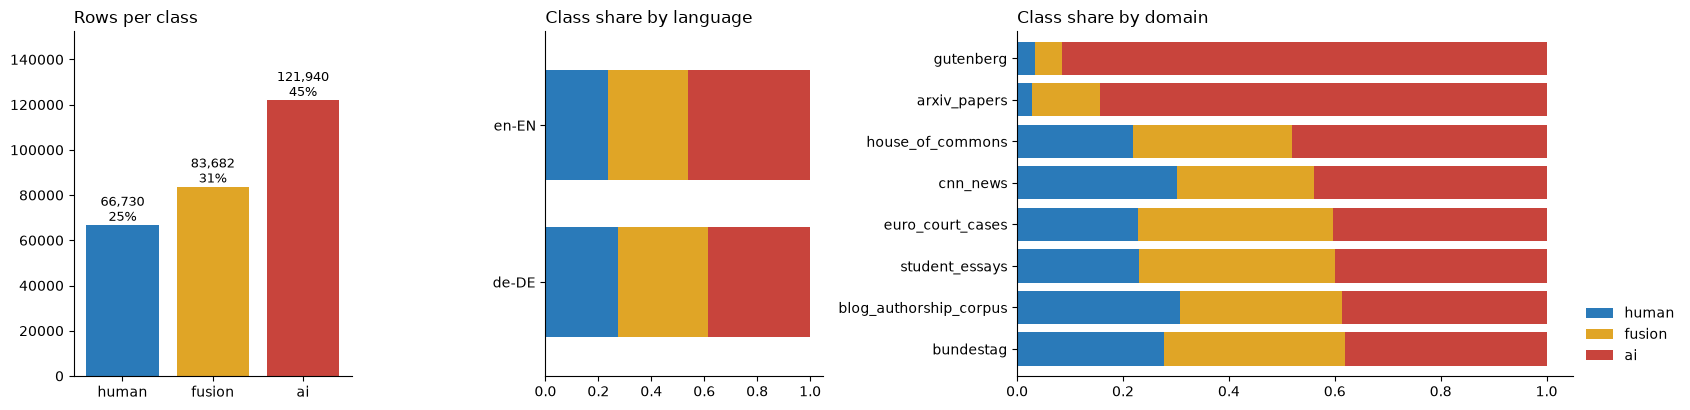

In [6]:
counts = train_df.label.value_counts().reindex(LABELS)
by_lang = pd.crosstab(train_df.lang, train_df.label, normalize='index')[LABELS]
by_domain = pd.crosstab(train_df.domain, train_df.label, normalize='index')[LABELS].sort_values('ai')
palette = [COLORS[c] for c in LABELS]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), gridspec_kw={'width_ratios': [1, 1, 2]})
axes[0].bar(counts.index, counts.values, color=palette)
for x, v in enumerate(counts.values):
    axes[0].text(x, v, f'{v:,}\n{v / counts.sum():.0%}', ha='center', va='bottom', fontsize=9)
axes[0].set_ylim(0, counts.max() * 1.25)
axes[0].set_title('Rows per class')
by_lang.plot.barh(stacked=True, ax=axes[1], color=palette, width=0.7, legend=False, title='Class share by language')
by_domain.plot.barh(stacked=True, ax=axes[2], color=palette, width=0.8, title='Class share by domain')
axes[2].legend(loc='lower left', bbox_to_anchor=(1, 0), frameon=False)
for ax in axes[1:]:
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

### Train vs test

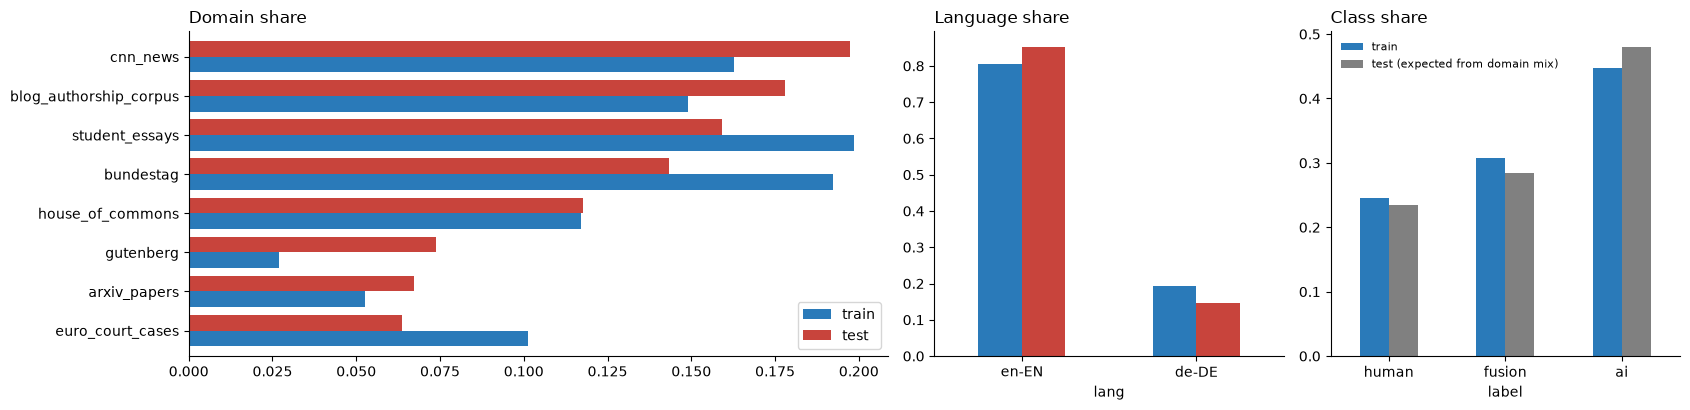

lang,de-DE,en-EN
domain,,
arxiv_papers,0,14290
blog_authorship_corpus,0,40547
bundestag,52343,0
cnn_news,0,44285
euro_court_cases,0,27578
gutenberg,428,6916
house_of_commons,0,31859
student_essays,0,54106


In [7]:
mix = pd.DataFrame({'train': train_df.domain.value_counts(normalize=True),
                    'test': test_df.domain.value_counts(normalize=True)}).sort_values('test')
langs = pd.DataFrame({'train': train_df.lang.value_counts(normalize=True),
                      'test': test_df.lang.value_counts(normalize=True)})
expected = pd.DataFrame({'train': counts / counts.sum(),
                         'test (expected from domain mix)': by_domain.mul(mix.test, axis=0).sum().reindex(LABELS)})

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), gridspec_kw={'width_ratios': [2, 1, 1]})
mix.plot.barh(ax=axes[0], color=[COLORS['train'], COLORS['test']], width=0.8, title='Domain share')
langs.plot.bar(ax=axes[1], color=[COLORS['train'], COLORS['test']], rot=0, legend=False, title='Language share')
expected.plot.bar(ax=axes[2], color=[COLORS['train'], 'gray'], rot=0, title='Class share')
axes[0].set_ylabel('')
axes[2].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

display(pd.crosstab(train_df.domain, train_df.lang))

### Text length

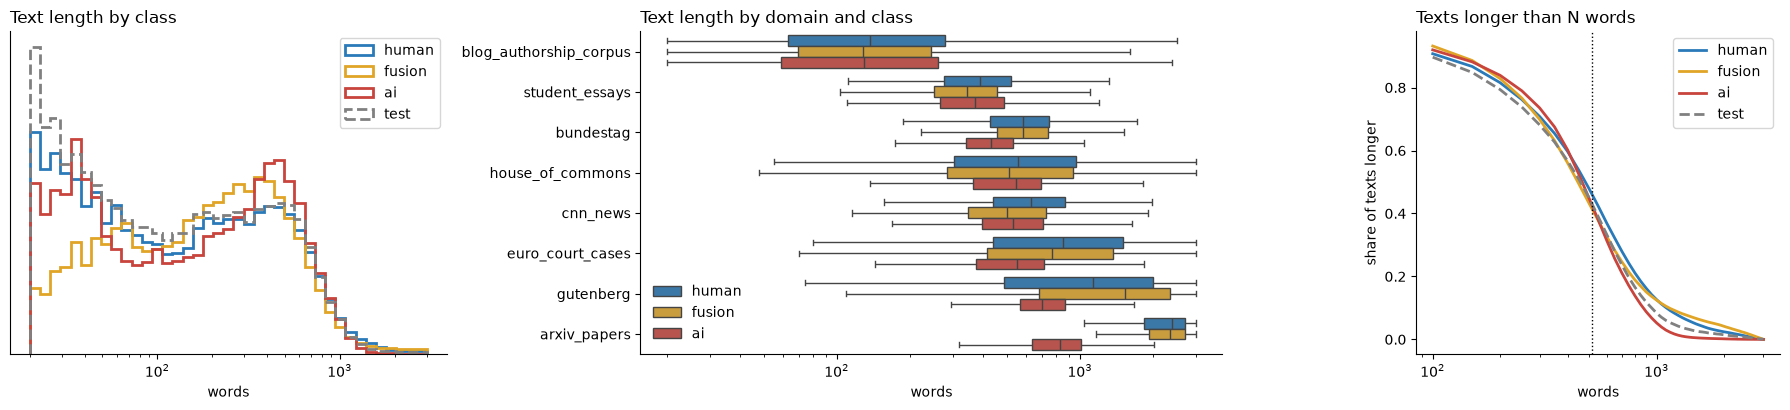

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2), gridspec_kw={'width_ratios': [1.2, 1.6, 1]})
bins = np.geomspace(20, 3000, 40)
for label in LABELS:
    axes[0].hist(train_df.words[train_df.label == label], bins=bins, density=True, histtype='step', lw=2,
                 color=COLORS[label], label=label)
axes[0].hist(test_df.words, bins=bins, density=True, histtype='step', lw=2, ls='--', color='gray', label='test')
axes[0].set(xscale='log', xlabel='words', yticks=[], title='Text length by class')
axes[0].legend()

order = train_df.groupby('domain').words.median().sort_values().index
sns.boxplot(data=train_df, x='words', y='domain', hue='label', hue_order=LABELS, order=order, palette=COLORS,
            showfliers=False, log_scale=True, ax=axes[1])
axes[1].set(ylabel='', title='Text length by domain and class')
axes[1].legend(frameon=False)

limits = np.arange(100, 3001, 50)
for label in LABELS:
    words = train_df.words[train_df.label == label].to_numpy()
    axes[2].plot(limits, [(words > n).mean() for n in limits], color=COLORS[label], lw=2, label=label)
axes[2].plot(limits, [(test_df.words > n).mean() for n in limits], color='gray', ls='--', lw=2, label='test')
axes[2].axvline(512, color='black', lw=1, ls=':')
axes[2].set(xscale='log', xlabel='words', ylabel='share of texts longer', title='Texts longer than N words')
axes[2].legend()
plt.tight_layout()
plt.show()

### Examples

In [9]:
def show_examples(domain, n_chars=600):
    rows = train_df[train_df.domain == domain].groupby('label').sample(1, random_state=SEED)
    for row in rows.set_index('label').reindex(LABELS).itertuples():
        print(f'--- {row.Index} ({row.lang}, {row.words} words)')
        print(textwrap.fill(row.text[:n_chars], 110), '...\n')


show_examples('cnn_news')
show_examples('bundestag')

--- human (en-EN, 439 words)
Luis Suarez looks set to be fit for Uruguay's clash with England in Sao Paulo on June 19 after saying his knee
is 'better'. The Liverpool striker needed surgery on his knee, leaving Uruguay sweating on the fitness of
their star striker. But, in a video message recorded for 888 poker, Suarez said he is on the road to recovery.
And the 27-year-old looked in fine form as he trained with the Uruguay squad just outside their base in Belo
Horizonte team on Tuesday. Road to recovery: Suarez said that his knee is getting 'better' ahead of the World
Cup . Fit and fresh: Suarez trained with the Uruguay ...

--- fusion (en-EN, 554 words)
A couple who were reported missing by police have been arrested for speeding through suburban streets and
crashing into motorists - with their newborn son on board. Ashley Groizard, 20, and Michael Holman, 32,
sparked a police search after disappearing with their son from the Hunter Valley in NSW, and were found by
authorities after b

### Fusion vs its human source

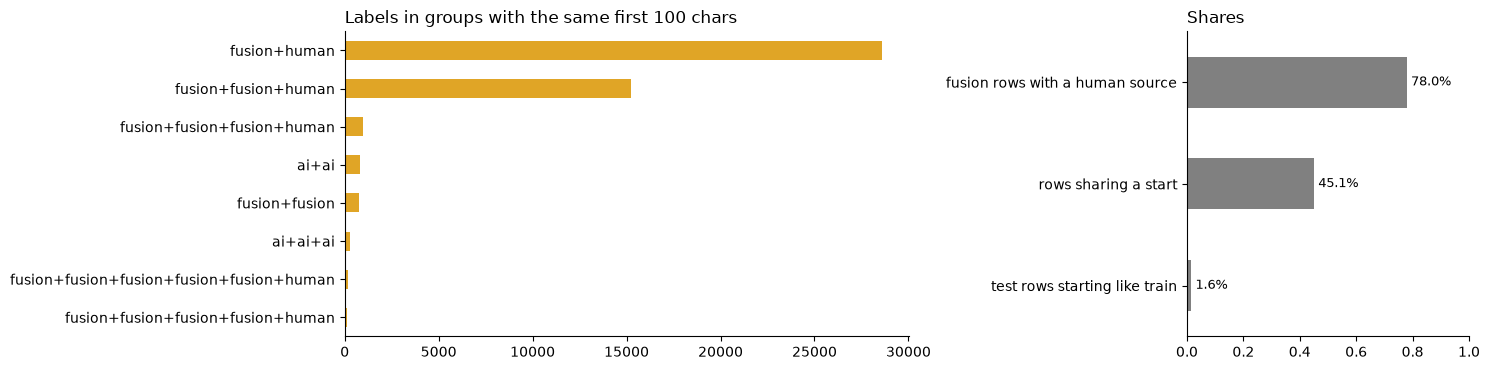

In [10]:
PREFIX_CHARS = 100
train_df['prefix'] = train_df.text.str[:PREFIX_CHARS]
shared = train_df[train_df.prefix.map(train_df.prefix.value_counts()) > 1]
combos = shared.groupby('prefix').label.agg(lambda s: '+'.join(sorted(s)))
fusion_with_source = train_df[train_df.label == 'fusion'].prefix.isin(
    set(train_df[train_df.label == 'human'].prefix)).mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={'width_ratios': [2, 1]})
combos.value_counts().head(8).sort_values().plot.barh(ax=axes[0], color=COLORS['fusion'],
                                                      title='Labels in groups with the same first 100 chars')
axes[0].set_ylabel('')
shares = pd.Series({'rows sharing a start': len(shared) / len(train_df),
                    'fusion rows with a human source': fusion_with_source,
                    'test rows starting like train': test_df.text.str[:PREFIX_CHARS].isin(set(train_df.prefix)).mean()})
shares.sort_values().plot.barh(ax=axes[1], color='gray', xlim=(0, 1), title='Shares')
for y, v in enumerate(shares.sort_values()):
    axes[1].text(v, y, f' {v:.1%}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

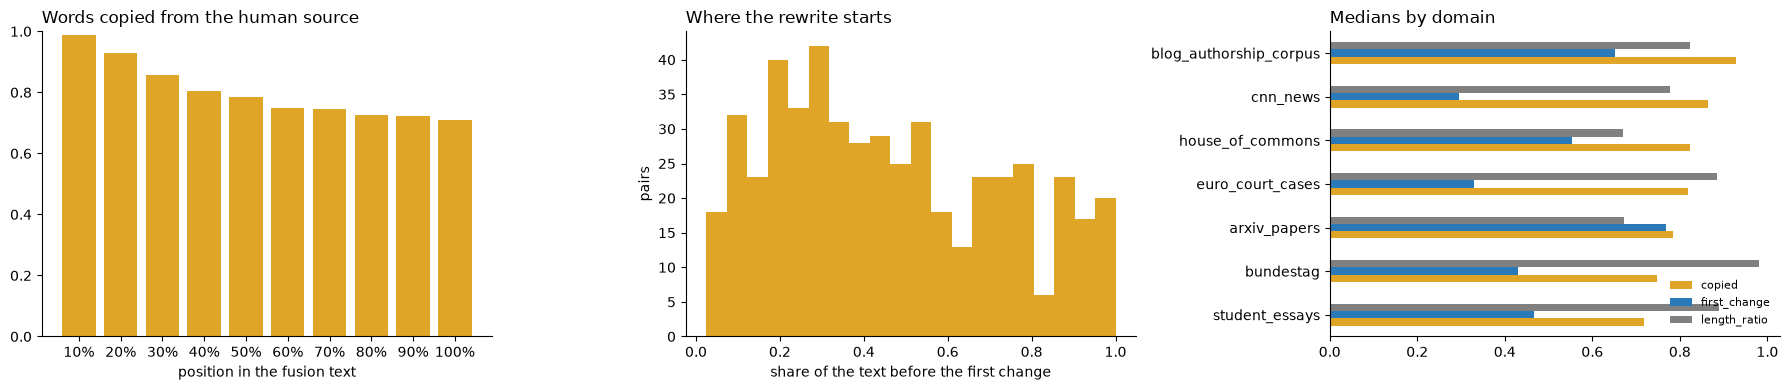

In [11]:
def compare_pair(human, fusion):
    h, f = human.split(), fusion.split()
    blocks = [b for b in SequenceMatcher(None, h, f, autojunk=False).get_matching_blocks() if b.size]
    copied = np.zeros(len(f), bool)
    for b in blocks:
        copied[b.b:b.b + b.size] = True
    first_change = blocks[0].size if blocks and blocks[0].a == blocks[0].b == 0 else 0
    return {'copied': copied.mean(), 'first_change': first_change / len(f), 'length_ratio': len(f) / len(h),
            'copied_by_tenth': [chunk.mean() for chunk in np.array_split(copied, 10)]}


pair_keys = combos[combos == 'fusion+human']
pair_keys = pair_keys.sample(min(500, len(pair_keys)), random_state=SEED).index
pairs = shared[shared.prefix.isin(pair_keys)].pivot(index='prefix', columns='label', values='text')
pair_stats = pd.DataFrame([compare_pair(r.human, r.fusion) for r in pairs.itertuples()])
pair_stats['domain'] = shared.drop_duplicates('prefix').set_index('prefix').domain.reindex(pairs.index).values
by_tenth = np.vstack(pair_stats.copied_by_tenth).mean(axis=0)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].bar(np.arange(1, 11), by_tenth, color=COLORS['fusion'])
axes[0].set_xticks(np.arange(1, 11), [f'{10 * k}%' for k in range(1, 11)])
axes[0].set(ylim=(0, 1), xlabel='position in the fusion text', title='Words copied from the human source')
axes[1].hist(pair_stats.first_change, bins=20, color=COLORS['fusion'])
axes[1].set(xlabel='share of the text before the first change', ylabel='pairs', title='Where the rewrite starts')
pair_stats.groupby('domain')[['copied', 'first_change', 'length_ratio']].median().sort_values('copied').plot.barh(
    ax=axes[2], color=[COLORS['fusion'], COLORS['human'], 'gray'], title='Medians by domain')
axes[2].set_ylabel('')
axes[2].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

In [12]:
row = pairs.iloc[0]
h, f = row.human.split(), row.fusion.split()
for tag, a1, a2, b1, b2 in SequenceMatcher(None, h, f, autojunk=False).get_opcodes()[:8]:
    if tag == 'equal':
        print(f'= {a2 - a1} words the same')
    else:
        print(f'{tag}\n  human:  {" ".join(h[a1:a2])[:150]}\n  fusion: {" ".join(f[b1:b2])[:150]}')

= 557 words the same
replace
  human:  In conclusion, the
  fusion: The
= 2 words the same
replace
  human:  should stay where
  fusion: may seem like an outdated system, but its benefits far outweigh any perceived inconveniences. It acts as a safeguard against rash decisions made by vo
= 1 words the same
replace
  human:  is because it was created by the founding fathers, it keeps communism and socialism out, and it is in the constitution. If the United States were to r
  fusion: fosters a broader understanding
= 2 words the same
replace
  human:  country itself, for they were the ones who fought for the freedom of the country.
  fusion: nation's needs and prevents candidates from focusing solely on densely populated areas.


### Surface style

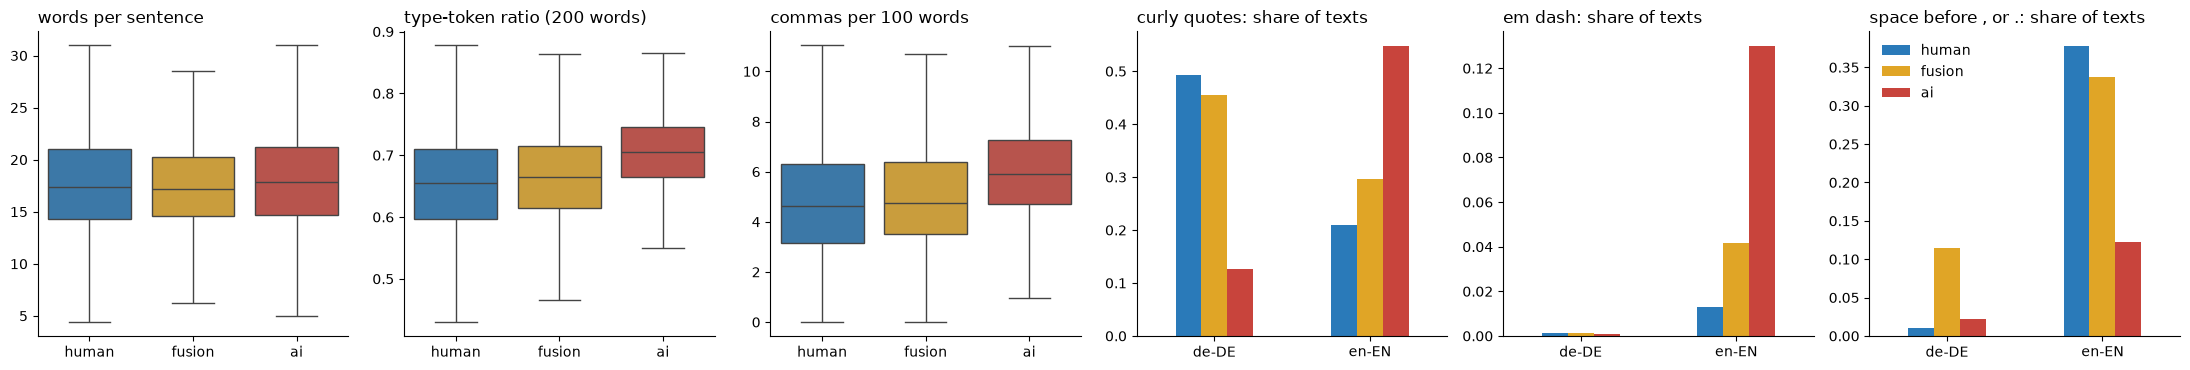

In [13]:
def style_features(text):
    words = text.split()
    sentences = [s for s in re.split(r'(?<=[.!?])\s+', text) if s]
    return {
        'words per sentence': len(words) / max(len(sentences), 1),
        'type-token ratio (200 words)': len(set(w.lower() for w in words[:200])) / min(len(words), 200),
        'commas per 100 words': 100 * text.count(',') / len(words),
        'curly quotes': any(c in text for c in '“”‘’„'),
        'em dash': '—' in text,
        'space before , or .': bool(re.search(r'\s[,.]', text)),
    }


style_rows = train_df.sample(30_000, random_state=SEED)
style = pd.DataFrame([style_features(t) for t in style_rows.text], index=style_rows.index)
style[['label', 'lang']] = style_rows[['label', 'lang']]
numeric, flags = list(style.columns[:3]), list(style.columns[3:6])

fig, axes = plt.subplots(1, 6, figsize=(22, 3.8))
for ax, col in zip(axes[:3], numeric):
    sns.boxplot(data=style, x='label', y=col, order=LABELS, hue='label', palette=COLORS, showfliers=False,
                legend=False, ax=ax)
    ax.set(xlabel='', ylabel='', title=col)
for ax, col in zip(axes[3:], flags):
    share = style.groupby(['lang', 'label'])[col].mean().unstack()[LABELS]
    share.plot.bar(ax=ax, color=palette, rot=0, legend=False, title=f'{col}: share of texts')
    ax.set_xlabel('')
axes[-1].legend(frameon=False)
plt.tight_layout()
plt.show()

## Validation split

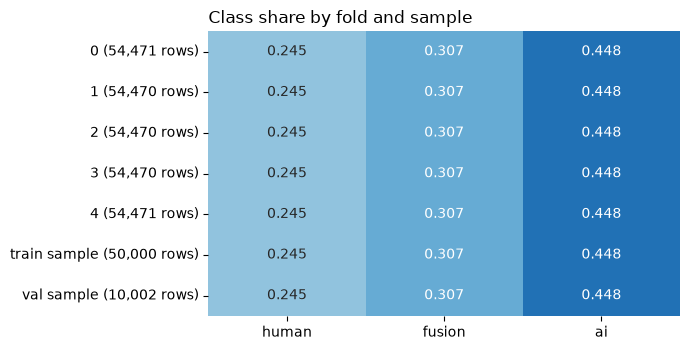

In [14]:
def stratified_sample(df, n):
    return df.groupby(['label', 'domain']).sample(frac=min(n / len(df), 1), random_state=SEED)


sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
train_df['fold'] = -1
for k, (_, rows) in enumerate(sgkf.split(train_df, train_df.label + '|' + train_df.domain, groups=train_df.prefix)):
    train_df.loc[train_df.index[rows], 'fold'] = k
assert (train_df.fold >= 0).all() and train_df.groupby('prefix').fold.nunique().max() == 1

is_val = train_df.fold == VAL_FOLD
train_part = stratified_sample(train_df[~is_val], TRAIN_SAMPLE)
val_part = stratified_sample(train_df[is_val], VAL_SAMPLE)
assert not set(train_part.prefix) & set(val_part.prefix)

splits = train_df[['id', 'fold']].assign(split=np.where(is_val, 'val', 'train')).set_index('id')
splits['in_sample'] = splits.index.isin(train_part.id) | splits.index.isin(val_part.id)
splits.to_csv(Path(RUNS) / 'splits.csv')

fold_share = pd.crosstab(train_df.fold, train_df.label, normalize='index')[LABELS]
fold_share.loc['train sample'] = train_part.label.value_counts(normalize=True)
fold_share.loc['val sample'] = val_part.label.value_counts(normalize=True)
fold_rows = train_df.fold.value_counts().sort_index().tolist() + [len(train_part), len(val_part)]

fig, ax = plt.subplots(figsize=(7, 3.6))
sns.heatmap(fold_share, annot=True, fmt='.3f', cmap='Blues', vmin=0, vmax=0.6, cbar=False, ax=ax)
ax.set_yticklabels([f'{i} ({n:,} rows)' for i, n in zip(fold_share.index, fold_rows)], rotation=0)
ax.set(xlabel='', ylabel='', title='Class share by fold and sample')
plt.tight_layout()
plt.show()

## Experiment helpers

In [15]:
TAG = 'full' if FULL_TRAIN else 'sample'


def cached(name, compute):
    file = Path(RUNS) / name
    if FORCE or not file.exists():
        start = time.time()
        compute().to_csv(file)
        print(f'{name}: {(time.time() - start) / 60:.1f} min')
    return pd.read_csv(file, index_col=0, converters={0: str})


def class_f1(y_true, y_pred, label):
    return f1_score(y_true, y_pred, labels=[label], average='macro')


SCORING = {'macro_f1': 'f1_macro', **{f'f1_{c}': make_scorer(class_f1, label=c) for c in LABELS}}


def plot_by_class(frame, columns, title):
    fig, axes = plt.subplots(1, len(columns), figsize=(5 * len(columns), 3.6))
    for ax, col in zip(np.atleast_1d(axes), columns):
        sns.boxplot(x=frame.label, y=frame[col], order=LABELS, hue=frame.label, palette=COLORS, showfliers=False,
                    legend=False, ax=ax)
        ax.set(xlabel='', ylabel='', title=col)
    fig.suptitle(title, x=0.01, ha='left')
    plt.tight_layout()
    plt.show()

## A. Text artefacts

In [16]:
MONTHS = 'January|February|March|April|May|June|July|August|September|October|November|December'
BRITISH = 'colour|favour|labour|honour|behaviour|neighbour|centre|organisation|recognise|realise|programme|defence|analyse'
AMERICAN = 'color|favor|labor|honor|behavior|neighbor|center|organization|recognize|realize|program|defense|analyze'

ARTIFACTS = {
    'symbols': {
        'apostrophe_straight': r"\w'\w",
        'apostrophe_curly': r'\w[’ʼ]\w',
        'apostrophe_other': r'\w[`´′]\w',
        'dquote_straight': r'"',
        'dquote_curly': r'[“”]',
        'dquote_low_de': r'„',
        'guillemets': r'[«»‹›]',
        'squote_low_de': r'‚',
        'squote_curly_open': r'‘',
        'hyphen_variants': r'[‐‑‒―]',
        'en_dash': r'–',
        'em_dash': r'—',
        'minus_sign': r'−',
        'double_hyphen': r'(?<!-)--(?!-)',
        'soft_hyphen': r'­',
        'ellipsis_char': r'…',
        'three_dots': r'(?<!\.)\.\.\.(?!\.)',
        'spaced_dots': r'\. \. \.',
        'starts_with_dots': r'^\s*(?:\.\.\.|…)',
        'nbsp_thin_space': r'[   ]',
        'zero_width_bom': r'[​‌‍﻿]',
        'ligature': r'[ﬀ-ﬆ]',
        'nfd_combining': r'[̀-ͯ]',
        'mixed_script_word': r'\b(?=\w*[A-Za-z])(?=\w*[Ͱ-ϿЀ-ӿ])\w+',
        'mojibake': r'â€|Ã[\u0080-¿]|Â[ -¿]',
        'bullet': r'[•·]',
        'special_symbol': r'[×°€£‰©™½]',
        'emoji': r'[\U0001F300-\U0001FAFF☀-➿]',
    },
    'spacing': {
        'space_before_punct': r'\w [,.;:!?](?=\s|$)',
        'space_inside_quotes': r'(?:^|\s)" \w',
        'ptb_contraction': r"\w (?:n't|'s|'re|'ll|'ve|'m|'d)\b",
        'double_punct': r'[!?]{2,}|,,',
        'no_space_after_period': r'[a-z]\.[A-Z][a-z]',
    },
    'source': {
        'empty_slot': r'\b(?:the|of|in|from|at|on|aged|v\.|NO\.|von|der)\s+[,.](?=\s)',
        'llm_placeholder': r'\[(?:Image|Photo|Name|Your Name|Insert|Date|Location|Company)[^\]]{0,60}\]|\bXYZ\b',
        'url': r'https?://|www\.',
        'mention_hashtag': r'(?:^|\s)[@#]\w',
        'email': r'\b[\w.+-]+@[\w-]+\.\w+',
        'html_entity': r'&(?:amp|quot|lt|gt|nbsp|#\d+);|<br\s*/?>',
        'markdown': r'\*\*|(?:^|\s)#{1,6} \w',
        'latex': r'\$[^$]{1,80}\$|\\(?:cite|ref|begin|frac|emph)\b',
        'timestamp_meta': r'\[\d{1,2}/\d{1,2}/\d{4} \d',
        'stage_direction': r'\((?:Beifall|Zuruf|Zurufe|Heiterkeit|Lachen|Widerspruch)[^)]{0,80}\)'
                           r'|\[(?:Interruption|Laughter)[^\]]{0,40}\]|Hon\. Members',
    },
    'numbers': {
        'number_en_format': r'\b\d{1,3}(?:,\d{3})+(?:\.\d+)?\b',
        'number_de_format': r'\b\d{1,3}(?:\.\d{3})+(?:,\d+)?\b',
        'date_words': rf'\b(?:{MONTHS}) \d{{1,2}}\b',
        'date_numeric': r'\b\d{1,2}[./]\d{1,2}[./]\d{2,4}\b',
        'currency_symbol': r'[$£€]\s?\d',
        'percent_word': r'\b(?:per cent|percent|Prozent)\b',
        'percent_sign': r'%',
        'n_year_old_digits': r'\b\d+-year-old\b',
    },
    'words': {
        'all_caps_word': r'\b[A-ZÄÖÜ]{4,}\b',
        'contraction': r"\b\w+(?:n't|'s|'re|'ll|'ve|'m|'d)\b",
        'de_abbreviation': r'\b(?:z\. ?B\.|d\. ?h\.|bzw\.|usw\.|ggf\.|u\. ?a\.)',
        'british_spelling': rf'\b(?:{BRITISH})\w*',
        'american_spelling': rf'\b(?:{AMERICAN})(?:s|ed|ing|ation)?\b',
    },
}
PATTERNS = {name: re.compile(p, re.M) for group in ARTIFACTS.values() for name, p in group.items()}
ARTIFACT_GROUP = {name: group for group, items in ARTIFACTS.items() for name in items}


def count_artifacts(texts):
    return pd.DataFrame({name: [len(p.findall(t)) for t in texts] for name, p in PATTERNS.items()}, index=texts.index)

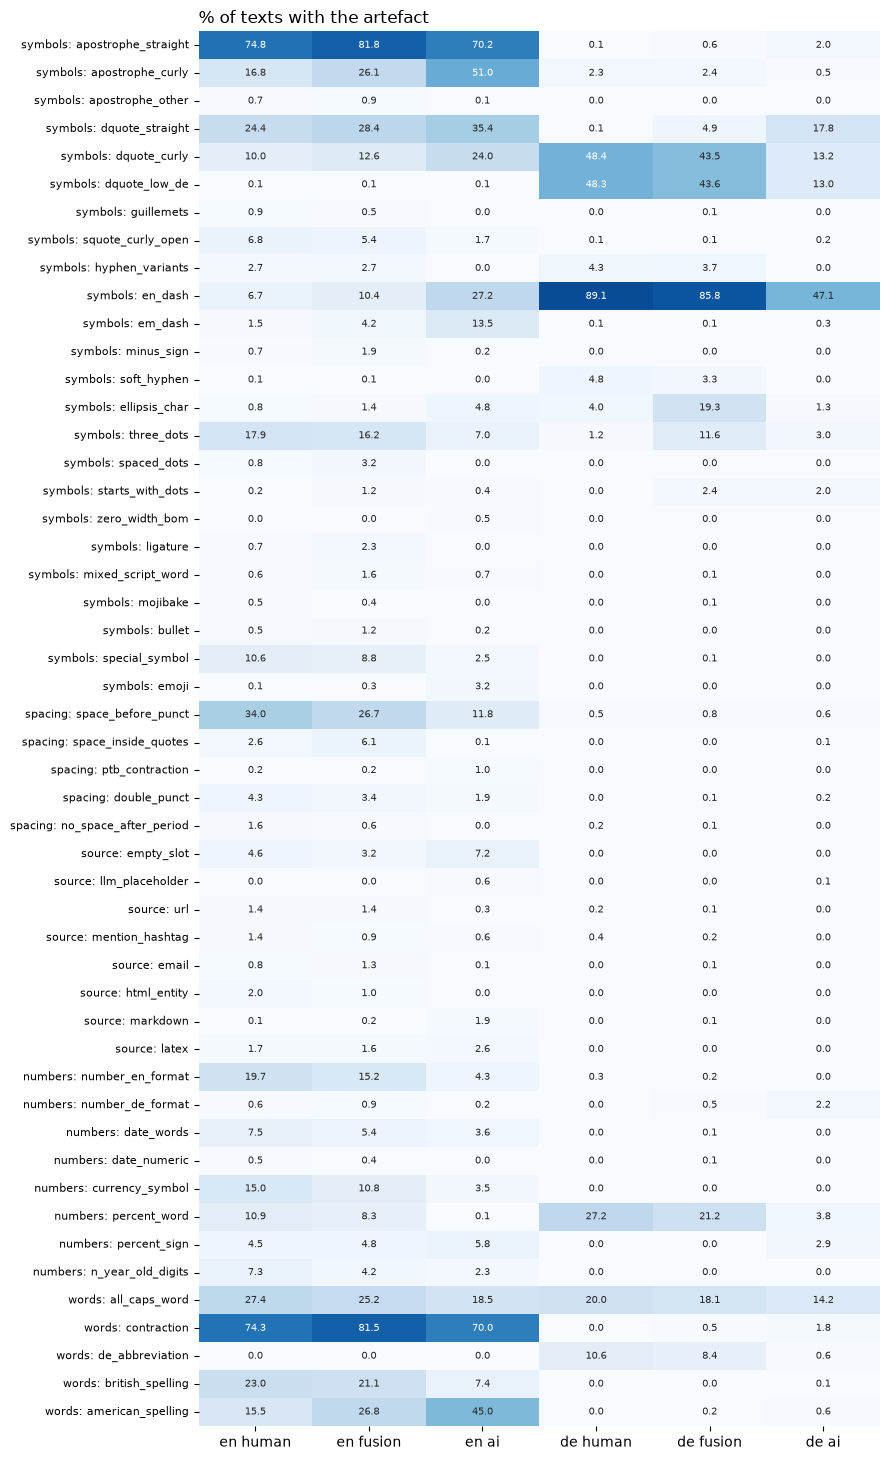

In [17]:
audit_rows = train_df[~is_val].sample(min(30_000, (~is_val).sum()), random_state=SEED)
audit = count_artifacts(audit_rows.text).gt(0).groupby([audit_rows.lang, audit_rows.label]).mean().T
audit = audit[[(lang, c) for lang in ['en-EN', 'de-DE'] for c in LABELS]]
shown = audit[(audit > 0.005).any(axis=1)]

fig, ax = plt.subplots(figsize=(9, 0.27 * len(shown) + 1.2))
sns.heatmap(shown * 100, annot=True, fmt='.1f', annot_kws={'fontsize': 7}, cmap='Blues', vmin=0, vmax=100,
            cbar=False, ax=ax)
ax.set_xticklabels([f'{lang[:2]} {c}' for lang, c in shown.columns])
ax.set_yticklabels([f'{ARTIFACT_GROUP[n]}: {n}' for n in shown.index], fontsize=8)
ax.set(xlabel='', ylabel='', title='% of texts with the artefact')
plt.tight_layout()
plt.show()

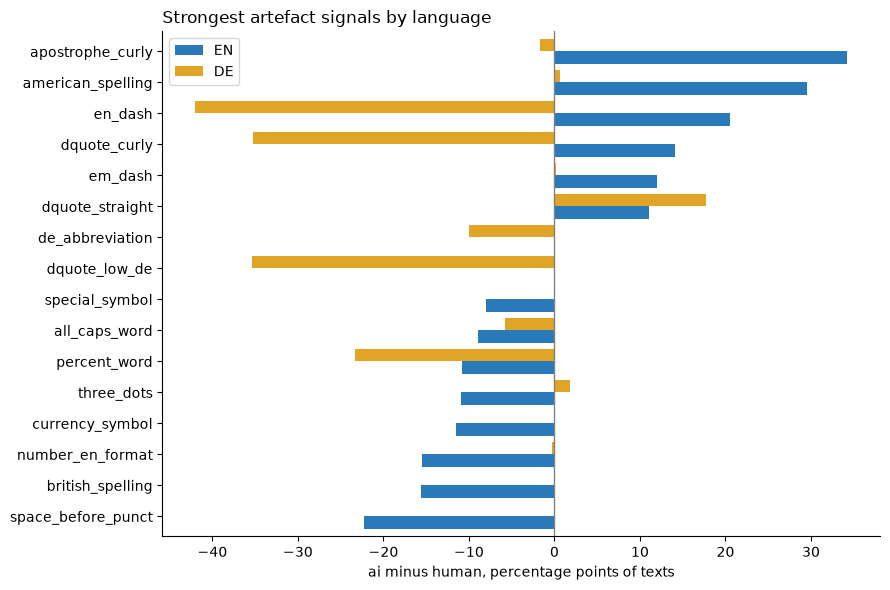

In [18]:
contrast = pd.DataFrame({lang[-2:]: audit[(lang, 'ai')] - audit[(lang, 'human')] for lang in ['en-EN', 'de-DE']}) * 100
top = contrast.loc[contrast.abs().max(axis=1).nlargest(16).index].sort_values('EN')

fig, ax = plt.subplots(figsize=(9, 6))
top.plot.barh(ax=ax, color=[COLORS['train'], COLORS['fusion']], width=0.8)
ax.axvline(0, color='gray', lw=1)
ax.set(xlabel='ai minus human, percentage points of texts', ylabel='', title='Strongest artefact signals by language')
plt.tight_layout()
plt.show()

## B. Normalisation search

In [19]:
QUOTES = str.maketrans({'“': '"', '”': '"', '„': '"', '«': '"', '»': '"',
                        '‹': "'", '›': "'", '‚': "'", '‘': "'", '’': "'",
                        'ʼ': "'", '`': "'", '´': "'", '′': "'"})
DASHES = str.maketrans({c: '-' for c in '‐‑‒–—―−'})
INVISIBLE = str.maketrans({'­': '', '​': '', '‌': '', '‍': '', '﻿': '',
                           ' ': ' ', ' ': ' ', ' ': ' '})
LIGATURES = re.compile(r'[ﬀ-ﬆ]')
SPACING = [
    (re.compile(r"(\w) (n't|'s|'re|'ll|'ve|'m|'d)\b"), r'\1\2'),
    (re.compile(r'(\w) ([,.;:!?])(?=\s|$)'), r'\1\2'),
    (re.compile(r'(^|\s)" (\w)'), r'\1"\2'),
    (re.compile(r'(\w) "(?=\s|$)'), r'\1"'),
    (re.compile(r'([a-z])\.([A-Z][a-z])'), r'\1. \2'),
]
WEB = [
    (re.compile(r'https?://\S+|www\.\S+'), ' URL '),
    (re.compile(r'\b[\w.+-]+@[\w-]+\.\w+'), ' EMAIL '),
    (re.compile(r'(^|\s)@+\w+'), r'\1@USER'),
]
NORM_FLAGS = ['unicode', 'web', 'quotes', 'dashes', 'ellipsis', 'spacing', 'digits', 'lowercase']


class TextNormalizer(BaseEstimator, TransformerMixin):
    def __init__(self, unicode=False, web=False, quotes=False, dashes=False, ellipsis=False, spacing=False,
                 digits=False, lowercase=False):
        self.unicode = unicode
        self.web = web
        self.quotes = quotes
        self.dashes = dashes
        self.ellipsis = ellipsis
        self.spacing = spacing
        self.digits = digits
        self.lowercase = lowercase

    def fit(self, X, y=None):
        return self

    def normalize(self, text):
        if self.unicode:
            text = unicodedata.normalize('NFC', text.translate(INVISIBLE))
            text = LIGATURES.sub(lambda m: unicodedata.normalize('NFKC', m.group()), text)
        if self.web:
            text = html.unescape(text)
            for pattern, repl in WEB:
                text = pattern.sub(repl, text)
        if self.quotes:
            text = text.translate(QUOTES)
        if self.dashes:
            text = text.translate(DASHES).replace('--', '-')
        if self.ellipsis:
            text = re.sub(r'…|\. \. \.', '...', text)
        if self.spacing:
            for pattern, repl in SPACING:
                text = pattern.sub(repl, text)
        if self.digits:
            text = re.sub(r'\d', '0', text)
        if self.lowercase:
            text = text.lower()
        return text

    def transform(self, X):
        return X.assign(clean=[self.normalize(t) for t in X.text])


class Stemmer(BaseEstimator, TransformerMixin):
    def __init__(self, enabled=False):
        self.enabled = enabled

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        if not self.enabled:
            return X['clean'].tolist()
        from nltk.stem.snowball import SnowballStemmer
        stemmers = {'en-EN': SnowballStemmer('english'), 'de-DE': SnowballStemmer('german')}
        seen = {lang: {} for lang in stemmers}
        out = []
        for text, lang in zip(X['clean'], X['lang']):
            stem, cache = stemmers[lang].stem, seen[lang]
            out.append(' '.join(cache[w] if w in cache else cache.setdefault(w, stem(w))
                                for w in re.findall(r'\w+', text)))
        return out


class ArtifactCounts(BaseEstimator, TransformerMixin):
    def __init__(self, groups=tuple(ARTIFACTS)):
        self.groups = groups

    def fit(self, X, y=None):
        self.names_ = [n for n in PATTERNS if ARTIFACT_GROUP[n] in self.groups]
        return self

    def transform(self, X):
        counts = np.array([[len(PATTERNS[n].findall(t)) for n in self.names_] for t in X.text], dtype=np.float32)
        chars = X.text.str.len().to_numpy(np.float32)[:, None]
        words = X.text.str.split().str.len().to_numpy(np.float32)[:, None]
        feats = np.hstack([np.log1p(1000 * counts / chars), np.log(chars), np.log(words)])
        is_de = (X.lang == 'de-DE').to_numpy(np.float32)[:, None]
        return sparse.csr_matrix(np.hstack([feats * (1 - is_de), feats * is_de]))


def make_text_model(model=None):
    tfidf = dict(sublinear_tf=True, lowercase=False, dtype=np.float32, min_df=3, max_features=300_000)
    return Pipeline([
        ('norm', TextNormalizer()),
        ('features', ColumnTransformer([
            ('char', TfidfVectorizer(analyzer='char', ngram_range=(1, 4), **tfidf), 'clean'),
            ('word', Pipeline([('stemmer', Stemmer()), ('tfidf', TfidfVectorizer(ngram_range=(1, 2), **tfidf))]),
             ['clean', 'lang']),
            ('art', Pipeline([('counts', ArtifactCounts()), ('scale', MaxAbsScaler())]), ['text', 'lang']),
        ])),
        ('model', model if model is not None else LinearSVC(C=0.5)),
    ])


print(TextNormalizer(unicode=True, quotes=True, dashes=True, spacing=True, web=True).normalize(
    'He said : do n\'t go “now” — see www.x.com &amp; the ﬁle.Then'))

He said: don't go "now" - see  URL  & the file. Then


In [20]:
search_rows = stratified_sample(train_df[~is_val], SEARCH_SAMPLE).sample(frac=1, random_state=SEED)
X_search, y_search = search_rows[['text', 'lang']], search_rows.label
search_cv = list(StratifiedGroupKFold(SEARCH_FOLDS, shuffle=True, random_state=SEED).split(
    X_search, y_search + '|' + search_rows.domain, groups=search_rows.prefix))


def run_search(name, make_search, labels=None):
    def compute():
        search = make_search().fit(X_search, y_search)
        res = pd.DataFrame(search.cv_results_)
        out = res[[c for c in res if c.startswith(('mean_test', 'std_test', 'split')) or c == 'mean_fit_time']].copy()
        out['params'] = [repr(p) for p in res.params]
        out.index = labels if labels is not None else [f'candidate {i}' for i in range(len(out))]
        return out
    return cached(f'{name}.csv', compute)


def grid_of(configs):
    return GridSearchCV(make_text_model(), [{k: [v] for k, v in p.items()} for p in configs.values()],
                        cv=search_cv, scoring=SCORING, refit=False, n_jobs=N_JOBS, error_score='raise')


def compare(results, reference):
    folds = [c for c in results if c.startswith('split') and c.endswith('_test_macro_f1')]
    diff = results[folds].sub(results.loc[reference, folds], axis=1)
    table = pd.DataFrame({'macro_f1': results.mean_test_macro_f1, 'delta': diff.mean(axis=1),
                          'delta_std': diff.std(axis=1),
                          'all_folds_agree': (np.sign(diff).nunique(axis=1) == 1) & diff.ne(0).all(axis=1)})
    for c in LABELS:
        table[f'delta_{c}'] = results[f'mean_test_f1_{c}'] - results.loc[reference, f'mean_test_f1_{c}']
    return table


def plot_search(table, title):
    rows = table.sort_values('delta')
    fig, axes = plt.subplots(1, 2, figsize=(16, 0.38 * len(rows) + 1.5), gridspec_kw={'width_ratios': [2, 1]})
    colors = np.where(rows.delta > 0, COLORS['up'], COLORS['down'])
    alphas = np.where(rows.all_folds_agree, 1.0, 0.35)
    for y, (d, s, c, a) in enumerate(zip(rows.delta, rows.delta_std, colors, alphas)):
        axes[0].barh(y, d, xerr=s, color=c, alpha=a)
    axes[0].set_yticks(range(len(rows)), rows.index)
    axes[0].axvline(0, color='gray', lw=1)
    axes[0].set(xlabel='macro-F1 vs reference (pale = folds disagree)', title=title)
    sns.heatmap(rows[[f'delta_{c}' for c in LABELS]].iloc[::-1], annot=True, fmt='+.3f', cmap='RdBu', center=0,
                cbar=False, yticklabels=False, xticklabels=LABELS, ax=axes[1])
    axes[1].set_title('F1 vs reference by class')
    plt.tight_layout()
    plt.show()

### B1. Normalisation and artefact blocks

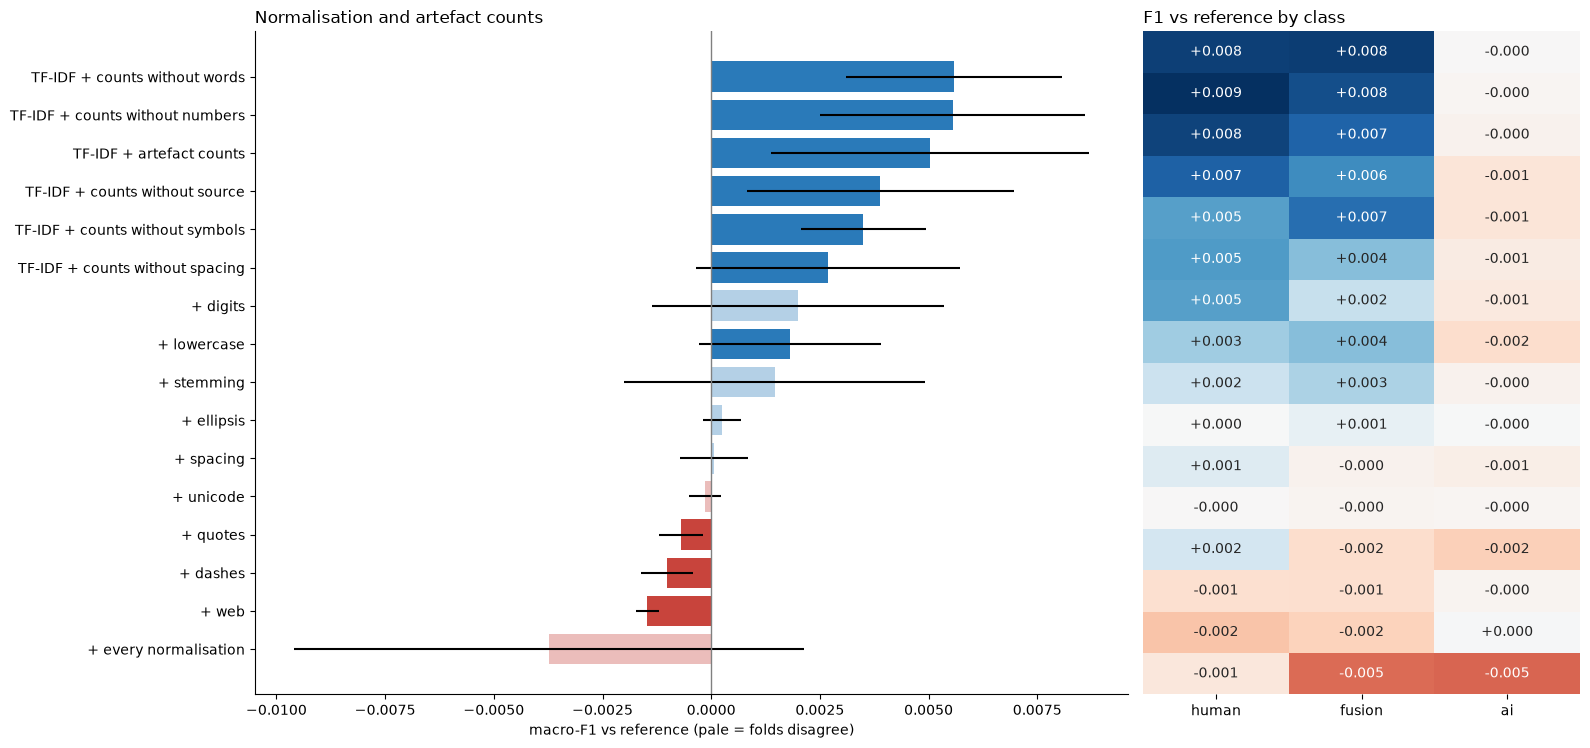

reference macro-F1 0.8268, artefact counts only 0.5802


In [21]:
TFIDF_ONLY = {'features__art': 'drop'}
REF_NORM = 'raw text, TF-IDF only'
norm_configs = {REF_NORM: TFIDF_ONLY}
norm_configs |= {f'+ {flag}': {**TFIDF_ONLY, f'norm__{flag}': True} for flag in NORM_FLAGS}
norm_configs['+ stemming'] = {**TFIDF_ONLY, 'features__word__stemmer__enabled': True}
norm_configs['+ every normalisation'] = {**TFIDF_ONLY, **{f'norm__{f}': True for f in NORM_FLAGS},
                                          'features__word__stemmer__enabled': True}
norm_configs['TF-IDF + artefact counts'] = {}
norm_configs |= {f'TF-IDF + counts without {g}': {'features__art__counts__groups': tuple(x for x in ARTIFACTS if x != g)}
                 for g in ARTIFACTS}
norm_configs['artefact counts only'] = {'features__char': 'drop', 'features__word': 'drop'}

norm_results = run_search('search_normalisation', lambda: grid_of(norm_configs), labels=list(norm_configs))
norm_table = compare(norm_results, REF_NORM)
plot_search(norm_table.drop(index=[REF_NORM, 'artefact counts only']), 'Normalisation and artefact counts')
print(f"reference macro-F1 {norm_table.macro_f1[REF_NORM]:.4f}, "
      f"artefact counts only {norm_table.macro_f1['artefact counts only']:.4f}")

### B2. Combined changes

combined: ['+ lowercase', 'TF-IDF + artefact counts', 'TF-IDF + counts without symbols', 'TF-IDF + counts without spacing', 'TF-IDF + counts without source', 'TF-IDF + counts without numbers', 'TF-IDF + counts without words']


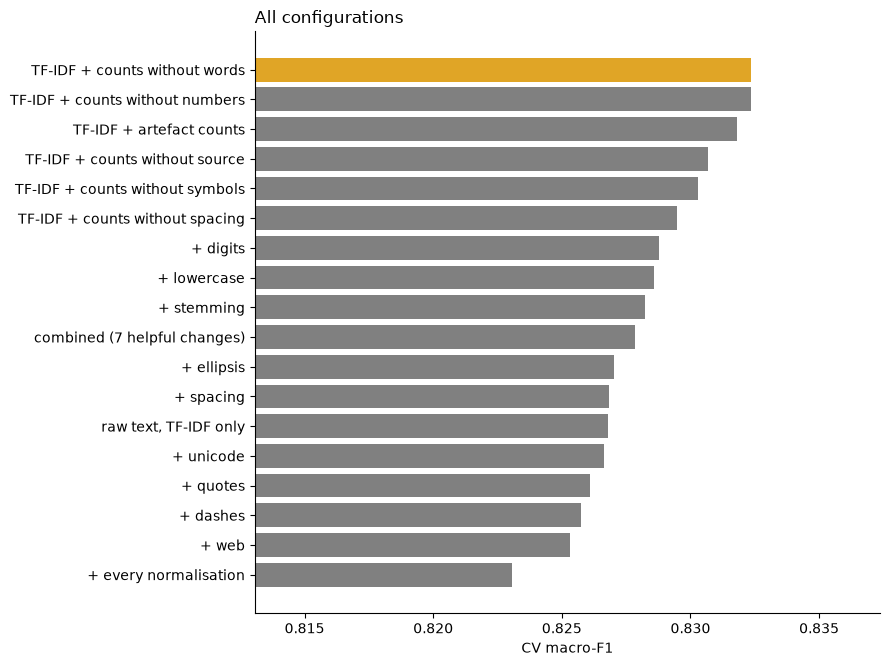

BASE_PARAMS from 'TF-IDF + counts without words' {'features__art__counts__groups': ('symbols', 'spacing', 'source', 'numbers')}


In [22]:
helpful = [n for n, r in norm_table.iterrows() if r.delta > 0 and r.all_folds_agree
           and n not in ('artefact counts only', '+ every normalisation')]
combined = {}
for name in helpful:
    combined |= norm_configs[name]
if any(n.startswith('TF-IDF + ') for n in helpful):
    combined.pop('features__art', None)
    dropped = [n.removeprefix('TF-IDF + counts without ') for n in helpful if 'without' in n]
    combined['features__art__counts__groups'] = tuple(g for g in ARTIFACTS if g not in dropped)

all_configs = dict(norm_configs)
if len(helpful) > 1:
    label = f'combined ({len(helpful)} helpful changes)'
    print('combined:', helpful)
    combo = run_search('search_normalisation_combined', lambda: grid_of({label: combined}), labels=[label])
    all_configs[label] = combined
    norm_results = pd.concat([norm_results, combo])
    norm_table = compare(norm_results, REF_NORM)

ranked = norm_table.drop(index='artefact counts only').sort_values('macro_f1')
fig, ax = plt.subplots(figsize=(9, 0.32 * len(ranked) + 1))
ax.barh(ranked.index, ranked.macro_f1, color=[COLORS['fusion'] if n == ranked.index[-1] else 'gray' for n in ranked.index])
ax.set(xlim=(ranked.macro_f1.min() - 0.01, ranked.macro_f1.max() + 0.005), xlabel='CV macro-F1', title='All configurations')
plt.tight_layout()
plt.show()

BASE_PARAMS = all_configs[ranked.index[-1]]
print('BASE_PARAMS from', repr(ranked.index[-1]), BASE_PARAMS)

## C. Baseline

### C1. Vectoriser search

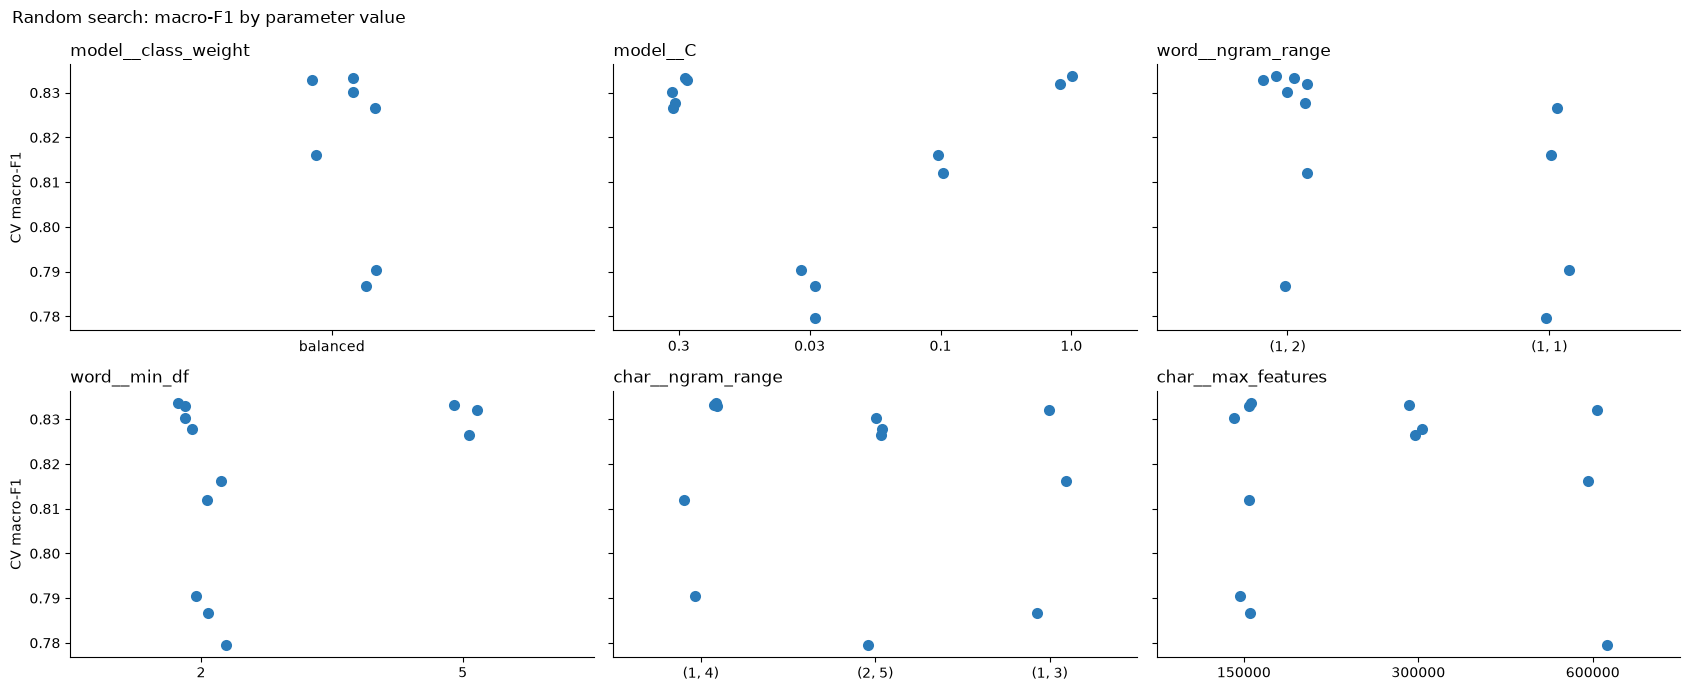

best CV macro-F1 0.8336: {'model__class_weight': None, 'model__C': 1.0, 'features__word__tfidf__ngram_range': (1, 2), 'features__word__tfidf__min_df': 2, 'features__char__ngram_range': (1, 4), 'features__char__max_features': 150000}


In [23]:
param_dist = {
    'features__char__ngram_range': [(1, 3), (1, 4), (2, 5)],
    'features__char__max_features': [150_000, 300_000, 600_000],
    'features__word__tfidf__ngram_range': [(1, 1), (1, 2)],
    'features__word__tfidf__min_df': [2, 5],
    'model__C': [0.03, 0.1, 0.3, 1.0],
    'model__class_weight': [None, 'balanced'],
}
vec_results = run_search('search_vectoriser', lambda: RandomizedSearchCV(
    make_text_model().set_params(**BASE_PARAMS), param_dist, n_iter=12, cv=search_cv, scoring=SCORING,
    refit=False, n_jobs=N_JOBS, random_state=SEED, error_score='raise'))

params = vec_results.params.map(ast.literal_eval).apply(pd.Series).rename(
    columns=lambda c: c.replace('features__', '').replace('tfidf__', ''))
vec = pd.concat([params.astype(str), vec_results[['mean_test_macro_f1', 'std_test_macro_f1']]], axis=1)

fig, axes = plt.subplots(2, 3, figsize=(17, 7), sharey=True)
for ax, col in zip(axes.flat, params.columns):
    sns.stripplot(data=vec, x=col, y='mean_test_macro_f1', color=COLORS['human'], size=8, ax=ax)
    ax.set(xlabel='', ylabel='CV macro-F1', title=col)
fig.suptitle('Random search: macro-F1 by parameter value', x=0.01, ha='left')
plt.tight_layout()
plt.show()

best_search = ast.literal_eval(vec_results.params[vec_results.mean_test_macro_f1.idxmax()])
VECTOR_PARAMS = {**BASE_PARAMS, **{k: v for k, v in best_search.items() if not k.startswith('model__')}}
SVC_PARAMS = {k.removeprefix('model__'): v for k, v in best_search.items() if k.startswith('model__')}
print(f'best CV macro-F1 {vec_results.mean_test_macro_f1.max():.4f}:', best_search)

### C2. Linear models

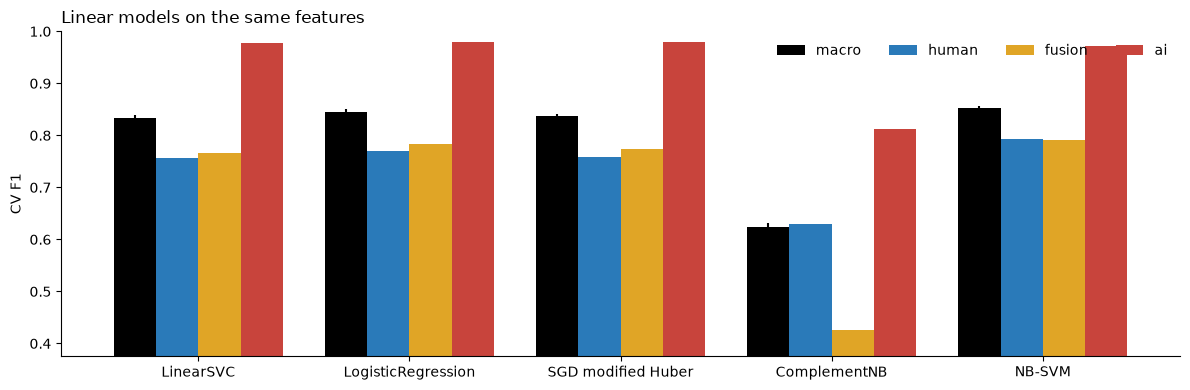

best linear model: NB-SVM


In [24]:
class NBSVM(BaseEstimator, ClassifierMixin):
    def __init__(self, C=4.0, alpha=1.0):
        self.C = C
        self.alpha = alpha

    def fit(self, X, y):
        X, y = sparse.csr_matrix(X), np.asarray(y)
        self.classes_ = np.unique(y)
        self.ratios_, self.models_ = [], []
        for c in self.classes_:
            p = self.alpha + np.asarray(X[y == c].sum(0)).ravel()
            q = self.alpha + np.asarray(X[y != c].sum(0)).ravel()
            r = np.log((p / p.sum()) / (q / q.sum())).astype(np.float32)
            self.ratios_.append(r)
            self.models_.append(LogisticRegression(C=self.C, solver='liblinear').fit(X.multiply(r).tocsr(), y == c))
        return self

    def decision_function(self, X):
        X = sparse.csr_matrix(X)
        return np.column_stack([m.decision_function(X.multiply(r).tocsr()) for r, m in zip(self.ratios_, self.models_)])

    def predict(self, X):
        return self.classes_[self.decision_function(X).argmax(1)]


weights = SVC_PARAMS.get('class_weight')
LINEAR_MODELS = {
    'LinearSVC': LinearSVC(**SVC_PARAMS),
    'LogisticRegression': LogisticRegression(C=10, max_iter=2000, class_weight=weights),
    'SGD modified Huber': SGDClassifier(loss='modified_huber', alpha=2e-5, class_weight=weights, random_state=SEED),
    'ComplementNB': ComplementNB(alpha=0.3),
    'NB-SVM': NBSVM(C=4.0),
}
linear_configs = {name: {**VECTOR_PARAMS, 'model': model} for name, model in LINEAR_MODELS.items()}
linear_results = run_search('search_linear_models', lambda: grid_of(linear_configs), labels=list(linear_configs))

scores = linear_results[['mean_test_macro_f1'] + [f'mean_test_f1_{c}' for c in LABELS]]
scores.columns = ['macro'] + LABELS
fig, ax = plt.subplots(figsize=(12, 4))
scores.plot.bar(ax=ax, color=['black'] + palette, rot=0, width=0.8,
                yerr={'macro': linear_results.std_test_macro_f1.to_numpy()})
ax.set(ylim=(max(0, scores.min().min() - 0.05), 1), ylabel='CV F1', title='Linear models on the same features')
ax.legend(ncol=4, frameon=False)
plt.tight_layout()
plt.show()

BEST_LINEAR = linear_results.mean_test_macro_f1.idxmax()
print('best linear model:', BEST_LINEAR)

### C3. Baseline on val

In [25]:
fit_rows = (train_df[~is_val] if FULL_TRAIN else train_part).set_index('id')
val_rows = val_part.set_index('id')
test_rows = test_df.set_index('id')
if SMOKE_TEST:
    test_rows = test_rows.head(500)
both_rows = pd.concat([fit_rows, val_rows])
all_ids = both_rows.index.union(test_rows.index)
y_val = val_rows.label
assert not set(fit_rows.prefix) & set(val_rows.prefix)
assert len(all_ids) == len(both_rows) + len(test_rows)
oof_cv = list(StratifiedGroupKFold(OOF_FOLDS, shuffle=True, random_state=SEED).split(
    fit_rows, fit_rows.label, groups=fit_rows.prefix))

RAM_GB = os.sysconf('SC_PAGE_SIZE') * os.sysconf('SC_PHYS_PAGES') / 2 ** 30
GB_PER_10K = 1.5
FIT_CAP = min(FIT_ROWS, int((RAM_GB - 10) / GB_PER_10K * 10_000))
PARALLEL_FITS = max(1, min(N_JOBS, int((RAM_GB - 10) // (GB_PER_10K * FIT_CAP / 10_000 + 1))))
CHUNK = 10_000
COLUMNS = ['text', 'lang', 'domain', 'label']
print(f'RAM {RAM_GB:.0f} GB: {PARALLEL_FITS} parallel fits of up to {FIT_CAP:,} rows, OOF on {len(fit_rows):,} rows')


def capped(rows, cap):
    return rows if cap is None or len(rows) <= cap else stratified_sample(rows, cap)


def fit_then_transform(fit_fn, transform_fn, train, apply):
    model = fit_fn(train)
    return pd.concat([transform_fn(model, apply.iloc[i:i + CHUNK]) for i in range(0, len(apply), CHUNK)])


def oof_features(name, fit_fn, transform_fn, cap=FIT_CAP, jobs=None):
    def tasks():
        rows = fit_rows[COLUMNS]
        for tr, te in oof_cv:
            yield capped(rows.iloc[tr], cap), rows.iloc[te]
        yield capped(rows, cap), pd.concat([val_rows[COLUMNS], test_rows[COLUMNS[:-1]]])

    def compute():
        return pd.concat(Parallel(n_jobs=jobs or PARALLEL_FITS)(
            delayed(fit_then_transform)(fit_fn, transform_fn, a, b) for a, b in tasks()))
    feats = cached(f'feat_{name}_{TAG}.csv', compute)
    assert feats.index.is_unique and feats.index.sort_values().equals(all_ids.sort_values())
    return feats


def fit_linear(rows):
    model = make_text_model(LINEAR_MODELS[BEST_LINEAR]).set_params(**VECTOR_PARAMS)
    return model.fit(rows[['text', 'lang']], rows.label)


def linear_scores(model, rows):
    X = rows[['text', 'lang']]
    scores = model.decision_function(X) if hasattr(model, 'decision_function') else model.predict_log_proba(X)
    return pd.DataFrame(scores, index=rows.index, columns=[f'lin_{c}' for c in model.classes_])


linear_feats = oof_features('linear', fit_linear, linear_scores)

RAM 62 GB: 3 parallel fits of up to 100,000 rows, OOF on 217,881 rows


baseline (NB-SVM): macro-F1 0.9055
              precision    recall  f1-score   support

          ai      0.985     0.994     0.990      4478
      fusion      0.920     0.817     0.866      3073
       human      0.814     0.914     0.861      2451

    accuracy                          0.920     10002
   macro avg      0.906     0.909     0.905     10002
weighted avg      0.923     0.920     0.920     10002



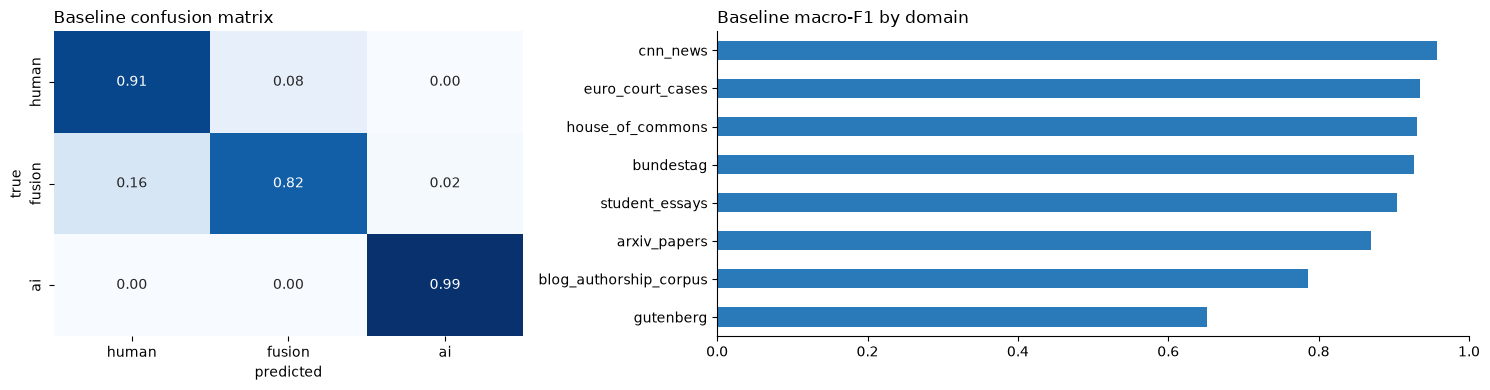

In [26]:
experiment_log, val_predictions = {}, {}
REFERENCE = f'baseline ({BEST_LINEAR})'


def to_label(scores):
    return scores.columns.str.split('_').str[-1].to_numpy()[scores.to_numpy().argmax(1)]


def evaluate(step, pred):
    val_predictions[step] = pd.Series(np.asarray(pred), index=val_rows.index)
    experiment_log[step] = {'macro_f1': f1_score(y_val, pred, average='macro'),
                            **{f'f1_{c}': class_f1(y_val, pred, c) for c in LABELS}}
    pd.DataFrame(experiment_log).T.to_csv(Path(RUNS) / f'experiment_log_{TAG}.csv')
    print(f"{step}: macro-F1 {experiment_log[step]['macro_f1']:.4f}")


def per_domain(steps):
    return pd.DataFrame({s: val_rows.assign(pred=val_predictions[s]).groupby('domain')[['label', 'pred']].apply(
        lambda g: f1_score(g.label, g.pred, average='macro')) for s in steps})


def plot_confusions(steps):
    fig, axes = plt.subplots(1, len(steps), figsize=(5 * len(steps), 4))
    for ax, step in zip(np.atleast_1d(axes), steps):
        cm = confusion_matrix(y_val, val_predictions[step], labels=LABELS, normalize='true')
        sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, cbar=False,
                    xticklabels=LABELS, yticklabels=LABELS, ax=ax)
        ax.set(xlabel='predicted', ylabel='true', title=step)
    plt.tight_layout()
    plt.show()


evaluate(REFERENCE, to_label(linear_feats.loc[val_rows.index]))
print(classification_report(y_val, val_predictions[REFERENCE], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={'width_ratios': [1, 1.6]})
cm = confusion_matrix(y_val, val_predictions[REFERENCE], labels=LABELS, normalize='true')
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, cbar=False, xticklabels=LABELS,
            yticklabels=LABELS, ax=axes[0])
axes[0].set(xlabel='predicted', ylabel='true', title='Baseline confusion matrix')
per_domain([REFERENCE])[REFERENCE].sort_values().plot.barh(ax=axes[1], color=COLORS['human'], xlim=(0, 1),
                                                           title='Baseline macro-F1 by domain')
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

## D. Experiments

### D1. Segment profile

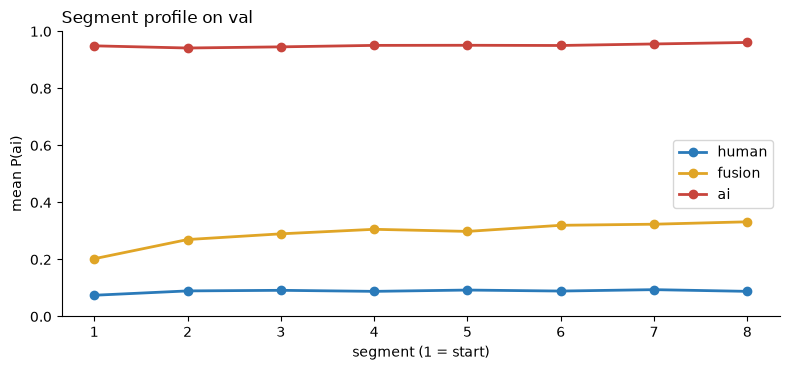

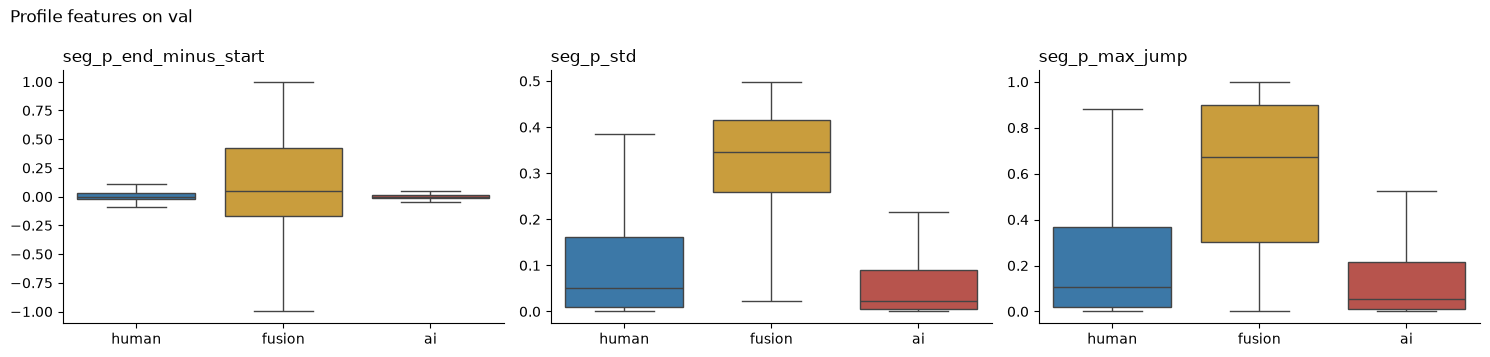

In [27]:
N_SEGMENTS = 8


def split_segments(text, k=N_SEGMENTS):
    return [' '.join(part) for part in np.array_split(text.split(), k)]


def fit_segment_model(rows):
    two = rows[rows.label != 'fusion']
    segments = [s for t in two.text for s in split_segments(t)]
    model = make_pipeline(
        TfidfVectorizer(analyzer='char', ngram_range=(1, 4), min_df=3, max_features=300_000, sublinear_tf=True,
                        lowercase=False, dtype=np.float32),
        LogisticRegression(C=4, max_iter=1000))
    return model.fit(segments, np.repeat((two.label == 'ai').to_numpy(), N_SEGMENTS))


def profile_features(p, prefix):
    f = pd.DataFrame(p, columns=[f'{prefix}{k + 1}' for k in range(N_SEGMENTS)])
    jumps = np.diff(p, axis=1)
    f[f'{prefix}_mean'] = p.mean(1)
    f[f'{prefix}_std'] = p.std(1)
    f[f'{prefix}_end_minus_start'] = p[:, -3:].mean(1) - p[:, :2].mean(1)
    f[f'{prefix}_range'] = p.max(1) - p.min(1)
    f[f'{prefix}_max_jump'] = jumps.max(1)
    f[f'{prefix}_max_jump_at'] = jumps.argmax(1) / N_SEGMENTS
    return f


def segment_profile(model, rows):
    segments = [s for t in rows.text for s in split_segments(t)]
    p = model.predict_proba(segments)[:, 1].reshape(len(rows), N_SEGMENTS)
    return profile_features(p, 'seg_p').set_index(rows.index)


segment_feats = oof_features('segments', fit_segment_model, segment_profile)
val_segments = segment_feats.loc[val_rows.index].assign(label=y_val)

fig, ax = plt.subplots(figsize=(8, 3.8))
profile = val_segments.filter(regex=r'^seg_p\d+$').groupby(y_val).mean()
for label in LABELS:
    ax.plot(range(1, N_SEGMENTS + 1), profile.loc[label], marker='o', lw=2, color=COLORS[label], label=label)
ax.set(xlabel='segment (1 = start)', ylabel='mean P(ai)', ylim=(0, 1), title='Segment profile on val')
ax.legend()
plt.tight_layout()
plt.show()
plot_by_class(val_segments, ['seg_p_end_minus_start', 'seg_p_std', 'seg_p_max_jump'], 'Profile features on val')

### D2. Character n-gram language models

feat_char_lm_full.csv: 4.0 min


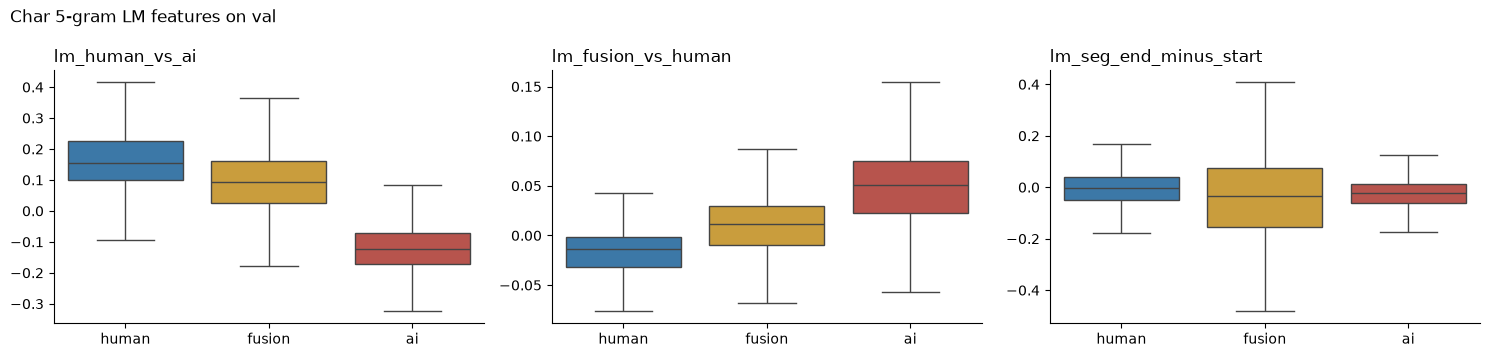

In [28]:
LM_N, LM_K, LM_ALPHABET, LM_BUCKETS = 5, 0.1, 300, 2 ** 22
LM_ORDERS = (LM_N, LM_N - 1)


def hash_ngrams(texts, n):
    return HashingVectorizer(analyzer='char', ngram_range=(n, n), lowercase=False, alternate_sign=False, norm=None,
                             n_features=LM_BUCKETS, dtype=np.float32).transform(texts)


def class_ngram_counts(rows):
    counts = np.zeros((len(LABELS), len(LM_ORDERS), LM_BUCKETS))
    for i, c in enumerate(LABELS):
        texts = rows.text[rows.label == c].tolist()
        for start in range(0, len(texts), 5_000):
            for j, n in enumerate(LM_ORDERS):
                counts[i, j] += np.asarray(hash_ngrams(texts[start:start + 5_000], n).sum(0)).ravel()
    return counts


def log_tables(counts):
    return np.stack([np.log(counts[:, 0] + LM_K), np.log(counts[:, 1] + LM_K * LM_ALPHABET)], 1).astype(np.float32)


def lm_loglik(texts, tables):
    ngrams = hash_ngrams(texts, LM_N)
    ll = ngrams @ tables[:, 0].T - hash_ngrams(texts, LM_N - 1) @ tables[:, 1].T
    return ll / np.maximum(np.asarray(ngrams.sum(1)).ravel(), 1)[:, None]


def char_lm_chunk(rows, tables):
    h, f, a = (LABELS.index(c) for c in ('human', 'fusion', 'ai'))
    texts = rows.text.tolist()
    doc = lm_loglik(texts, tables)
    seg = lm_loglik([s for t in texts for s in split_segments(t)], tables).reshape(len(rows), N_SEGMENTS, -1)
    out = profile_features(seg[:, :, h] - seg[:, :, a], 'lm_seg')
    out['lm_human_vs_ai'] = doc[:, h] - doc[:, a]
    out['lm_fusion_vs_ai'] = doc[:, f] - doc[:, a]
    out['lm_fusion_vs_human'] = doc[:, f] - doc[:, h]
    out['lm_ai_loglik'] = doc[:, a]
    return out.set_index(rows.index)


def char_lm_all():
    folds = [fit_rows.iloc[te][['text', 'label']] for _, te in oof_cv]
    fold_counts = Parallel(n_jobs=N_JOBS)(delayed(class_ngram_counts)(rows) for rows in folds)
    total = np.sum(fold_counts, axis=0)
    jobs = [(rows[['text']], log_tables(total - counts)) for rows, counts in zip(folds, fold_counts)]
    jobs.append((pd.concat([val_rows, test_rows])[['text']], log_tables(total)))
    del fold_counts, total
    return pd.concat(Parallel(n_jobs=N_JOBS)(delayed(char_lm_chunk)(rows.iloc[i:i + CHUNK], tables)
                                             for rows, tables in jobs for i in range(0, len(rows), CHUNK)))


char_lm_feats = cached(f'feat_char_lm_{TAG}.csv', char_lm_all)
assert char_lm_feats.index.is_unique and char_lm_feats.index.sort_values().equals(all_ids.sort_values())
plot_by_class(char_lm_feats.loc[val_rows.index].assign(label=y_val),
              ['lm_human_vs_ai', 'lm_fusion_vs_human', 'lm_seg_end_minus_start'], 'Char 5-gram LM features on val')

### D3. Compression and dense features

feat_dense_full.csv: 1.5 min


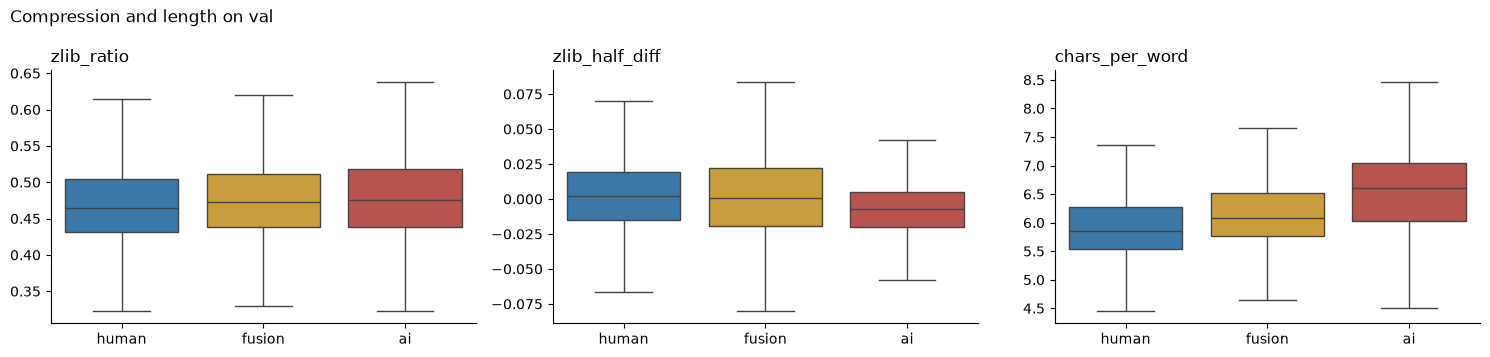

In [29]:
def compression_ratio(text):
    data = text.encode()
    return len(zlib.compress(data, 9)) / len(data)


def dense_features(rows):
    chars, words = rows.text.str.len(), rows.text.str.split().str.len()
    first = rows.text.map(lambda t: compression_ratio(t[:len(t) // 2]))
    second = rows.text.map(lambda t: compression_ratio(t[len(t) // 2:]))
    f = pd.DataFrame({'log_chars': np.log(chars), 'log_words': np.log(words), 'chars_per_word': chars / words,
                      'is_de': (rows.lang == 'de-DE').astype(int), 'zlib_ratio': rows.text.map(compression_ratio),
                      'zlib_first_half': first, 'zlib_second_half': second, 'zlib_half_diff': second - first},
                     index=rows.index)
    art = count_artifacts(rows.text).div(chars, axis=0).mul(1000).add_prefix('art_')
    domains = pd.get_dummies(rows.domain, prefix='domain', dtype=int).reindex(
        columns=[f'domain_{d}' for d in DOMAINS], fill_value=0)
    return pd.concat([f, art, domains], axis=1)


DOMAINS = sorted(train_df.domain.unique())
dense_rows = pd.concat([both_rows, test_rows])[['text', 'lang', 'domain']]
dense = cached(f'feat_dense_{TAG}.csv', lambda: pd.concat(Parallel(n_jobs=N_JOBS)(
    delayed(dense_features)(dense_rows.iloc[i:i + CHUNK]) for i in range(0, len(dense_rows), CHUNK))))
plot_by_class(dense.loc[val_rows.index].assign(label=y_val), ['zlib_ratio', 'zlib_half_diff', 'chars_per_word'],
              'Compression and length on val')

### D4. LM perplexity (GPU)

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

perplexity:   0%|          | 0/31611 [00:00<?, ?it/s]

feat_perplexity_full.csv: 91.2 min


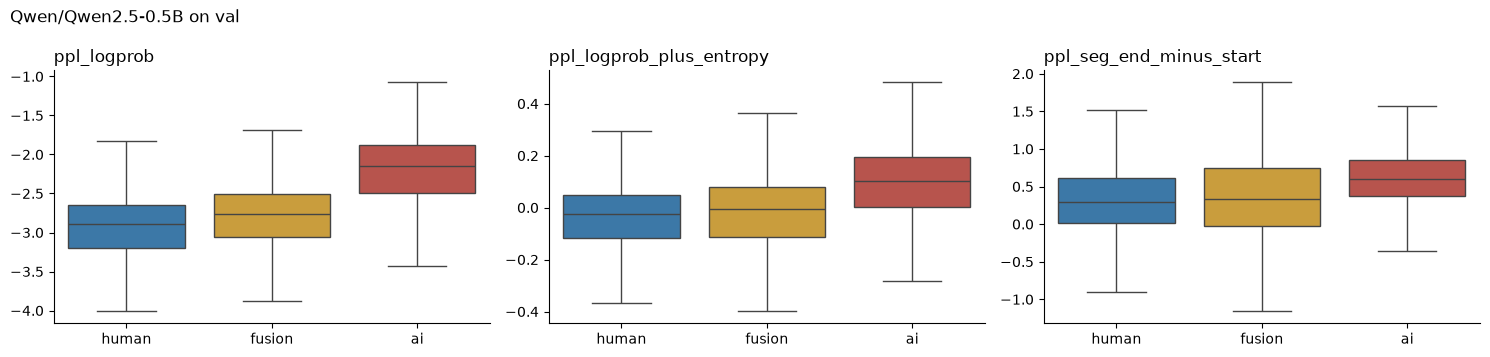

In [30]:
def token_ids(tokenizer, texts, transform):
    out = []
    for start in range(0, len(texts), CHUNK):
        ids = tokenizer(texts[start:start + CHUNK], add_special_tokens=False).input_ids
        out += [np.asarray(transform(x), np.int32) for x in ids]
    return out


def make_batches(seqs, batch_size, pad, shuffle=False, seed=SEED):
    lengths = np.fromiter(map(len, seqs), int, len(seqs))
    order = np.random.default_rng(seed).permutation(len(seqs)) if shuffle else np.argsort(lengths)
    for start in range(0, len(order), batch_size):
        idx = order[start:start + batch_size]
        ids = torch.full((len(idx), lengths[idx].max()), pad, dtype=torch.long)
        mask = torch.zeros_like(ids)
        for row, i in enumerate(idx):
            ids[row, :lengths[i]] = torch.from_numpy(seqs[i])
            mask[row, :lengths[i]] = 1
        yield idx, ids, mask


def perplexity_features(rows, device=DEVICE):
    tokenizer = AutoTokenizer.from_pretrained(LM_NAME)
    model = AutoModelForCausalLM.from_pretrained(LM_NAME, dtype=torch.bfloat16).to(device).eval()
    pad = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0
    half = LM_MAX_TOKENS // 2
    ids = token_ids(tokenizer, rows.text.tolist(), lambda x: x if len(x) <= LM_MAX_TOKENS else x[:half] + x[-half:])
    out = np.zeros((len(ids), 4 + 2 * N_SEGMENTS), np.float32)
    for batch, input_ids, mask in tqdm(make_batches(ids, LM_BATCH, pad), total=-(-len(ids) // LM_BATCH),
                                       desc='perplexity'):
        with torch.inference_mode():
            input_ids = input_ids.to(device)
            logits = model(input_ids=input_ids, attention_mask=mask.to(device)).logits[:, :-1]
            logp = torch.log_softmax(logits.float(), -1)
            del logits
            token_lp = logp.gather(-1, input_ids[:, 1:, None])[..., 0].cpu().numpy()
            entropy = -logp.exp().mul_(logp).sum(-1).cpu().numpy()
            del logp
        for row, i in enumerate(batch):
            n = len(ids[i]) - 1
            lp, ent = token_lp[row, :n], entropy[row, :n]
            out[i] = [lp.mean(), lp.std(), ent.mean(), lp.mean() + ent.mean(),
                      *[s.mean() for s in np.array_split(lp, N_SEGMENTS)],
                      *[s.mean() for s in np.array_split(ent, N_SEGMENTS)]]
    columns = (['ppl_logprob', 'ppl_logprob_std', 'ppl_entropy', 'ppl_logprob_plus_entropy']
               + [f'ppl_seg_lp{k + 1}' for k in range(N_SEGMENTS)] + [f'ppl_seg_ent{k + 1}' for k in range(N_SEGMENTS)])
    f = pd.DataFrame(out, index=rows.index, columns=columns)
    seg_lp = f.filter(regex=r'^ppl_seg_lp').to_numpy()
    f['ppl_seg_end_minus_start'] = seg_lp[:, -3:].mean(1) - seg_lp[:, :2].mean(1)
    return f


ppl_file = Path(RUNS) / f'feat_perplexity_{TAG}.csv'
if RUN_PERPLEXITY and (FORCE or not ppl_file.exists()):
    cached(ppl_file.name, lambda: perplexity_features(pd.concat([both_rows, test_rows])))
ppl_feats = pd.read_csv(ppl_file, index_col=0, converters={0: str}) if ppl_file.exists() else None
if ppl_feats is None:
    print('skipped: RUN_PERPLEXITY = False')
else:
    plot_by_class(ppl_feats.loc[val_rows.index].assign(label=y_val),
                  ['ppl_logprob', 'ppl_logprob_plus_entropy', 'ppl_seg_end_minus_start'], f'{LM_NAME} on val')

### D5. fastText

In [31]:
try:
    import fasttext
except ImportError:
    fasttext = None


def fit_fasttext(rows):
    file = Path(RUNS) / f'fasttext_{uuid.uuid4().hex}.txt'
    file.write_text(''.join(f'__label__{label} {text}\n' for label, text in zip(rows.label, rows.text)))
    model = fasttext.train_supervised(str(file), minn=2, maxn=5, wordNgrams=2, dim=100, epoch=10, lr=0.5,
                                      verbose=0, seed=SEED)
    file.unlink()
    return model


def fasttext_features(model, rows):
    labels, probs = model.predict(rows.text.tolist(), k=len(LABELS))
    out = pd.DataFrame([dict(zip(ls, ps)) for ls, ps in zip(labels, probs)], index=rows.index)
    return out.rename(columns=lambda c: 'ft_' + c.removeprefix('__label__'))[[f'ft_{c}' for c in LABELS]]


ft_file = Path(RUNS) / f'feat_fasttext_{TAG}.csv'
ft_feats = None
if fasttext is not None or ft_file.exists():
    ft_feats = oof_features('fasttext', fit_fasttext, fasttext_features, cap=None, jobs=1)
    evaluate('fastText', to_label(ft_feats.loc[val_rows.index]))
else:
    print('skipped: fasttext is not installed')

skipped: fasttext is not installed


### D6. Stacking

/home/akulba/Desktop/kulbaba-ucu-ai-hw-3/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


stack: baseline scores: macro-F1 0.9126


/home/akulba/Desktop/kulbaba-ucu-ai-hw-3/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


stack: + length, artefacts, domain: macro-F1 0.9215


/home/akulba/Desktop/kulbaba-ucu-ai-hw-3/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


stack: + compression: macro-F1 0.9213


... (4 outputs left out)

/home/akulba/Desktop/kulbaba-ucu-ai-hw-3/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


stack: + LM perplexity: macro-F1 0.9328


/home/akulba/Desktop/kulbaba-ucu-ai-hw-3/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


stack: all but baseline scores: macro-F1 0.9143


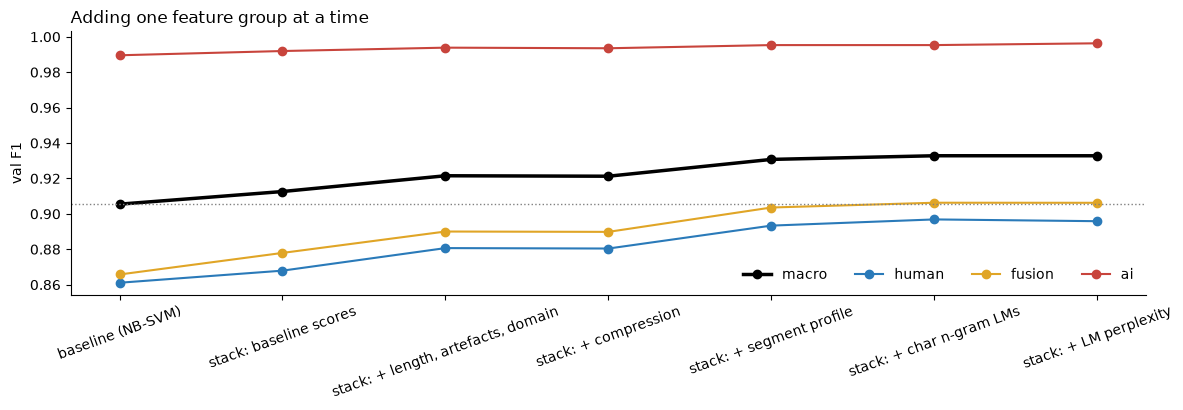

In [33]:
LGB_PARAMS = dict(n_estimators=3000, learning_rate=0.03, num_leaves=63, min_child_samples=40, subsample=0.8,
                  subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, n_jobs=os.cpu_count(),
                  verbose=-1)
FEATURE_GROUPS = {name: f for name, f in {
    'baseline scores': linear_feats,
    'length, artefacts, domain': dense.drop(columns=dense.filter(like='zlib').columns),
    'compression': dense.filter(like='zlib'),
    'segment profile': segment_feats,
    'char n-gram LMs': char_lm_feats,
    'LM perplexity': ppl_feats,
    'fastText': ft_feats,
}.items() if f is not None}


def stack_matrix(groups, rows):
    return pd.concat([FEATURE_GROUPS[g].loc[rows.index] for g in groups], axis=1)


def fit_lgb(X, y):
    tr, te = oof_cv[0]
    probe = lgb.LGBMClassifier(**LGB_PARAMS).fit(X.iloc[tr], y.iloc[tr], eval_set=[(X.iloc[te], y.iloc[te])],
                                                 callbacks=[lgb.early_stopping(100, verbose=False)])
    return lgb.LGBMClassifier(**{**LGB_PARAMS, 'n_estimators': probe.best_iteration_}).fit(X, y)


def run_stack(step, groups):
    model = fit_lgb(stack_matrix(groups, fit_rows), fit_rows.label)
    evaluate(step, model.predict(stack_matrix(groups, val_rows)))
    return model


stack_steps = []
for i, name in enumerate(FEATURE_GROUPS):
    step = 'stack: baseline scores' if i == 0 else f'stack: + {name}'
    stack_model = run_stack(step, list(FEATURE_GROUPS)[:i + 1])
    stack_steps.append(step)
run_stack('stack: all but baseline scores', [g for g in FEATURE_GROUPS if g != 'baseline scores'])
FINAL_GROUPS = list(FEATURE_GROUPS)

progress = pd.DataFrame(experiment_log).T.loc[[REFERENCE] + stack_steps]
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(progress.index, progress.macro_f1, color='black', marker='o', lw=2.5, label='macro')
for c in LABELS:
    ax.plot(progress.index, progress[f'f1_{c}'], color=COLORS[c], marker='o', lw=1.5, label=c)
ax.axhline(progress.macro_f1.iloc[0], color='gray', ls=':', lw=1)
ax.set(ylabel='val F1', title='Adding one feature group at a time')
ax.tick_params(axis='x', rotation=20)
ax.legend(frameon=False, ncol=4)
plt.tight_layout()
plt.show()

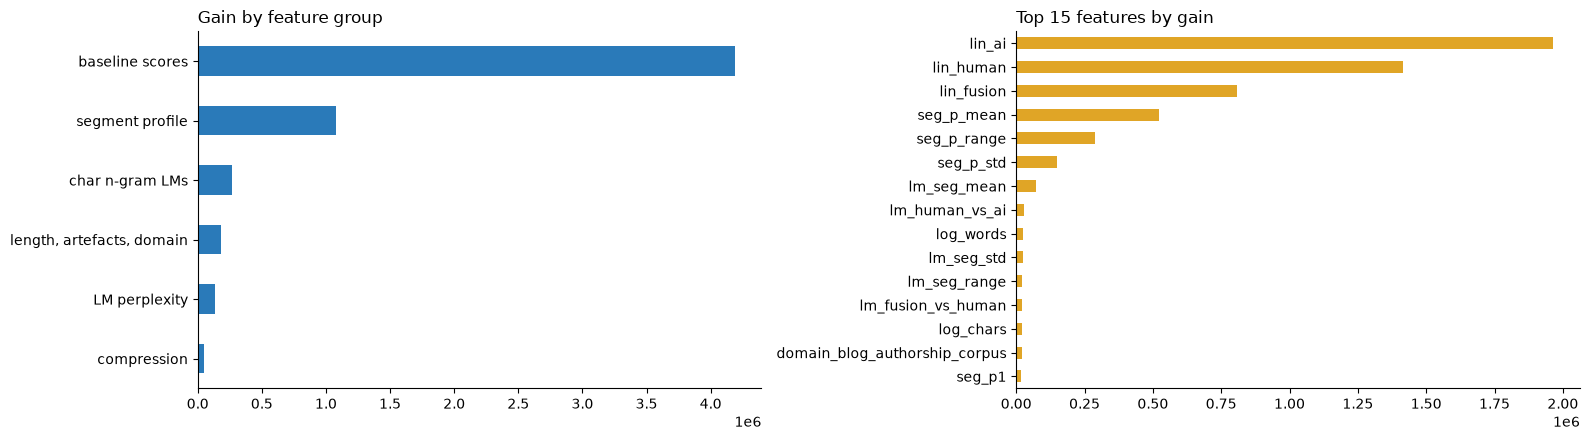

In [34]:
columns = stack_matrix(FINAL_GROUPS, val_rows.iloc[:1]).columns
group_of = {col: g for g in FINAL_GROUPS for col in FEATURE_GROUPS[g].columns}
gain = pd.Series(stack_model.booster_.feature_importance('gain'), index=columns)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
gain.groupby(group_of).sum().sort_values().plot.barh(ax=axes[0], color=COLORS['human'], title='Gain by feature group')
gain.nlargest(15).sort_values().plot.barh(ax=axes[1], color=COLORS['fusion'], title='Top 15 features by gain')
plt.tight_layout()
plt.show()

### D7. Class offsets for macro-F1

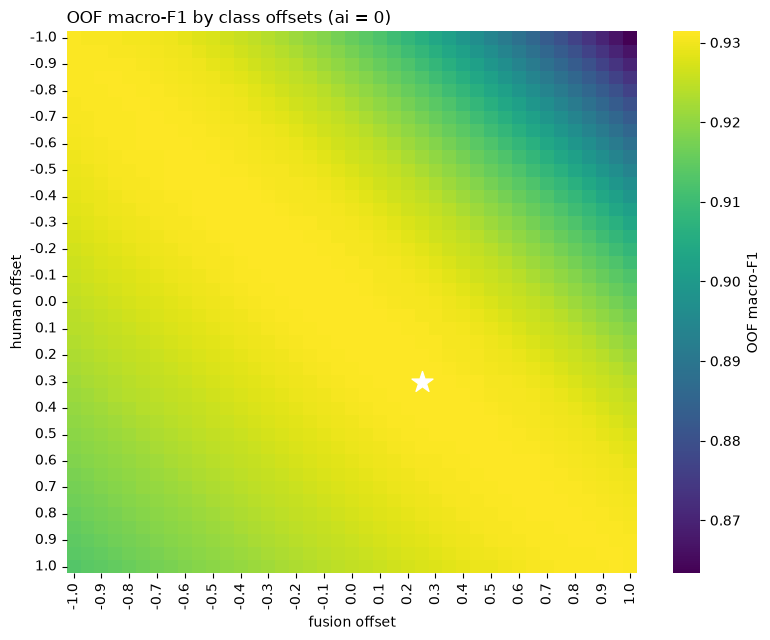

stack + class offsets: macro-F1 0.9329
offsets: human +0.3, fusion +0.2


In [35]:
def apply_offsets(proba, offsets):
    return np.array(LABELS)[(np.log(proba + 1e-9) + offsets).argmax(1)]


X_fit = stack_matrix(FINAL_GROUPS, fit_rows)
oof_proba = np.zeros((len(fit_rows), len(LABELS)))
for tr, te in oof_cv:
    model = lgb.LGBMClassifier(**{**LGB_PARAMS, 'n_estimators': stack_model.n_estimators}).fit(
        X_fit.iloc[tr], fit_rows.label.iloc[tr])
    oof_proba[te] = pd.DataFrame(model.predict_proba(X_fit.iloc[te]), columns=model.classes_)[LABELS].to_numpy()

def fast_macro_f1(y, pred, k=len(LABELS)):
    cm = np.bincount(y * k + pred, minlength=k * k).reshape(k, k)
    tp = np.diag(cm)
    return np.mean(2 * tp / np.maximum(cm.sum(0) + cm.sum(1), 1))


y_fit = fit_rows.label.map({c: i for i, c in enumerate(LABELS)}).to_numpy()
log_oof = np.log(oof_proba + 1e-9)
grid = np.round(np.arange(-1.0, 1.01, 0.05), 2)
surface = pd.DataFrame([[fast_macro_f1(y_fit, (log_oof + [h, f, 0.0]).argmax(1)) for f in grid] for h in grid],
                       index=grid, columns=grid)
best_h, best_f = surface.stack().idxmax()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(surface, cmap='viridis', ax=ax, cbar_kws={'label': 'OOF macro-F1'})
ax.scatter(list(grid).index(best_f) + 0.5, list(grid).index(best_h) + 0.5, marker='*', s=250, color='white')
ax.set(xlabel='fusion offset', ylabel='human offset', title='OOF macro-F1 by class offsets (ai = 0)')
plt.tight_layout()
plt.show()

val_proba = pd.DataFrame(stack_model.predict_proba(stack_matrix(FINAL_GROUPS, val_rows)),
                         columns=stack_model.classes_)[LABELS].to_numpy()
evaluate('stack + class offsets', apply_offsets(val_proba, [best_h, best_f, 0.0]))
print(f'offsets: human {best_h:+.1f}, fusion {best_f:+.1f}')

## E. Encoder

### E1. Fine-tuning with head + tail truncation

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] Token indices sequence length is longer than the specified maximum sequence len

epoch 1:   0%|          | 0/13618 [00:00<?, ?it/s]

epoch 2:   0%|          | 0/13618 [00:00<?, ?it/s]

encoder_proba_xlm-roberta-base_full.csv: 83.0 min


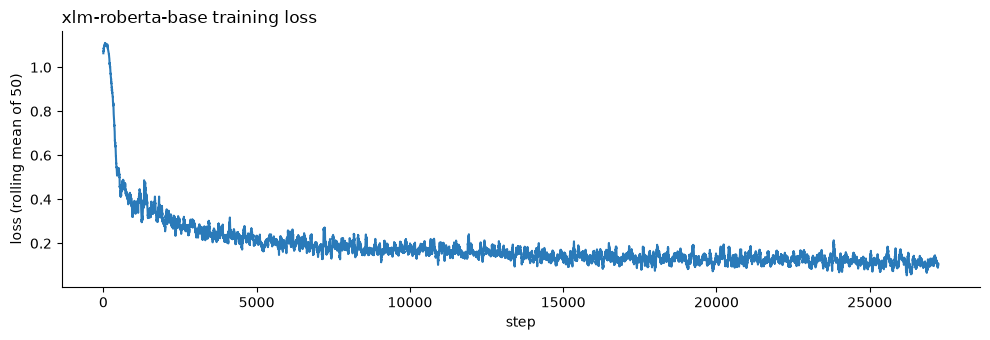

In [36]:
LABEL_ID = {c: i for i, c in enumerate(LABELS)}
ENCODER_MODES = ['head', 'head_tail', 'chunks']


def cut(ids, mode, body):
    if len(ids) <= body:
        return ids
    return ids[:body] if mode == 'head' else np.concatenate([ids[:body // 2], ids[len(ids) - (body - body // 2):]])


def special_tokens(tokenizer):
    cls, sep = [tokenizer.cls_token_id], [tokenizer.sep_token_id]
    return lambda ids: np.concatenate([cls, ids, sep]).astype(np.int32)


def predict_proba(model, seqs, pad, device):
    model.eval()
    out = np.zeros((len(seqs), len(LABELS)), np.float32)
    with torch.inference_mode(), torch.autocast(device, dtype=torch.bfloat16):
        for idx, ids, mask in make_batches(seqs, ENCODER_BATCH * 4, pad):
            logits = model(input_ids=ids.to(device), attention_mask=mask.to(device)).logits.float()
            out[idx] = torch.softmax(logits, -1).cpu().numpy()
    return out


def encoder_proba(model, tokenizer, rows, device):
    body = ENCODER_MAX_LEN - 2
    full = token_ids(tokenizer, rows.text.tolist(), np.asarray)
    wrap = special_tokens(tokenizer)
    pad = tokenizer.pad_token_id
    result = {mode: predict_proba(model, [wrap(cut(ids, mode, body)) for ids in full], pad, device)
              for mode in ['head', 'head_tail']}
    chunks, owner = [], []
    for i, ids in enumerate(full):
        for start in range(0, max(len(ids), 1), body):
            chunks.append(wrap(ids[start:start + body]))
            owner.append(i)
    chunk_proba = predict_proba(model, chunks, pad, device)
    result['chunks'] = pd.DataFrame(chunk_proba).groupby(np.array(owner)).mean().to_numpy()
    return pd.concat([pd.DataFrame(p, index=rows.index, columns=[f'{m}_{c}' for c in LABELS])
                      for m, p in result.items()], axis=1)


def train_encoder(rows, apply_rows, device=DEVICE):
    torch.manual_seed(SEED)
    tokenizer = AutoTokenizer.from_pretrained(ENCODER_NAME)
    model = AutoModelForSequenceClassification.from_pretrained(ENCODER_NAME, num_labels=len(LABELS)).to(device)
    body = ENCODER_MAX_LEN - 2
    wrap = special_tokens(tokenizer)
    seqs = token_ids(tokenizer, rows.text.tolist(), lambda x: wrap(cut(np.asarray(x), 'head_tail', body)))
    target = torch.tensor(rows.label.map(LABEL_ID).to_numpy())
    per_epoch = -(-len(seqs) // ENCODER_BATCH)
    steps = ENCODER_EPOCHS * per_epoch
    optimizer = torch.optim.AdamW(model.parameters(), lr=ENCODER_LR, weight_decay=0.01, fused=True)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.06 * steps), steps)
    losses = []
    for epoch in range(ENCODER_EPOCHS):
        model.train()
        batches = make_batches(seqs, ENCODER_BATCH, tokenizer.pad_token_id, shuffle=True, seed=SEED + epoch)
        for idx, ids, mask in tqdm(batches, total=per_epoch, desc=f'epoch {epoch + 1}'):
            with torch.autocast(device, dtype=torch.bfloat16):
                logits = model(input_ids=ids.to(device, non_blocking=True),
                               attention_mask=mask.to(device, non_blocking=True)).logits
            loss = torch.nn.functional.cross_entropy(logits.float(), target[idx].to(device))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
            losses.append(loss.detach())
    pd.Series(torch.stack(losses).float().cpu().numpy(), name='loss').to_csv(
        Path(RUNS) / f'encoder_loss_{ENCODER_SLUG}.csv')
    return encoder_proba(model, tokenizer, apply_rows, device)


ENCODER_SLUG = f"{ENCODER_NAME.split('/')[-1]}_{TAG}"
encoder_file = Path(RUNS) / f'encoder_proba_{ENCODER_SLUG}.csv'
if RUN_ENCODER and (FORCE or not encoder_file.exists()):
    cached(encoder_file.name, lambda: train_encoder(fit_rows, pd.concat([val_rows, test_rows])))
encoder_proba_all = pd.read_csv(encoder_file, index_col=0, converters={0: str}) if encoder_file.exists() else None

if encoder_proba_all is None:
    print('skipped: RUN_ENCODER = False')
else:
    loss = pd.read_csv(Path(RUNS) / f'encoder_loss_{ENCODER_SLUG}.csv', index_col=0).loss
    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.plot(loss.rolling(50, min_periods=1).mean(), color=COLORS['human'])
    ax.set(xlabel='step', ylabel='loss (rolling mean of 50)', title=f'{ENCODER_NAME} training loss')
    plt.tight_layout()
    plt.show()

### E2. Long-text handling

encoder: head: macro-F1 0.8153
encoder: head_tail: macro-F1 0.9345
encoder: chunks: macro-F1 0.8447


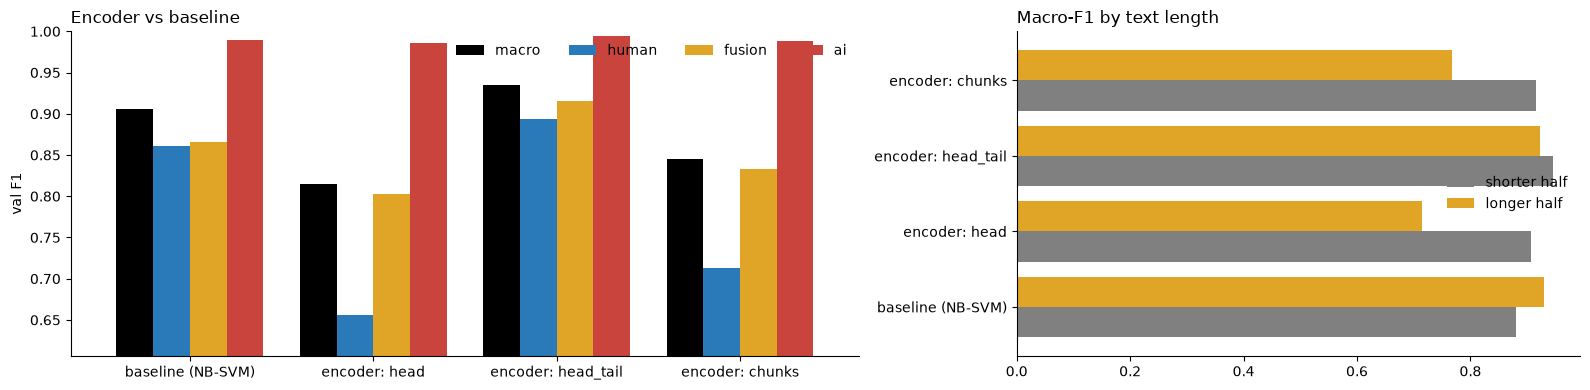

In [37]:
if encoder_proba_all is not None:
    encoder_val = encoder_proba_all.loc[val_rows.index]
    for mode in ENCODER_MODES:
        evaluate(f'encoder: {mode}', to_label(encoder_val[[f'{mode}_{c}' for c in LABELS]]))

    modes = pd.DataFrame(experiment_log).T.loc[[REFERENCE] + [f'encoder: {m}' for m in ENCODER_MODES]]
    modes.columns = ['macro'] + LABELS
    fig, axes = plt.subplots(1, 2, figsize=(16, 4), gridspec_kw={'width_ratios': [1.4, 1]})
    modes.plot.bar(ax=axes[0], color=['black'] + palette, rot=0, width=0.8)
    axes[0].set(ylim=(max(0, modes.min().min() - 0.05), 1), ylabel='val F1', title='Encoder vs baseline')
    axes[0].legend(ncol=4, frameon=False)
    long_text = val_rows.words > val_rows.words.median()
    by_length = pd.DataFrame({step: [f1_score(y_val[m], val_predictions[step][m], average='macro')
                                     for m in (~long_text, long_text)] for step in modes.index},
                             index=['shorter half', 'longer half']).T
    by_length.plot.barh(ax=axes[1], color=['gray', COLORS['fusion']], width=0.8, title='Macro-F1 by text length')
    axes[1].legend(frameon=False)
    plt.tight_layout()
    plt.show()

### E3. Encoder + stack

In [38]:
if encoder_proba_all is not None:
    encoder_head_tail = encoder_val[[f'head_tail_{c}' for c in LABELS]].to_numpy()
    evaluate('stack + encoder', np.array(LABELS)[(val_proba + encoder_head_tail).argmax(1)])

stack + encoder: macro-F1 0.9544


## Summary

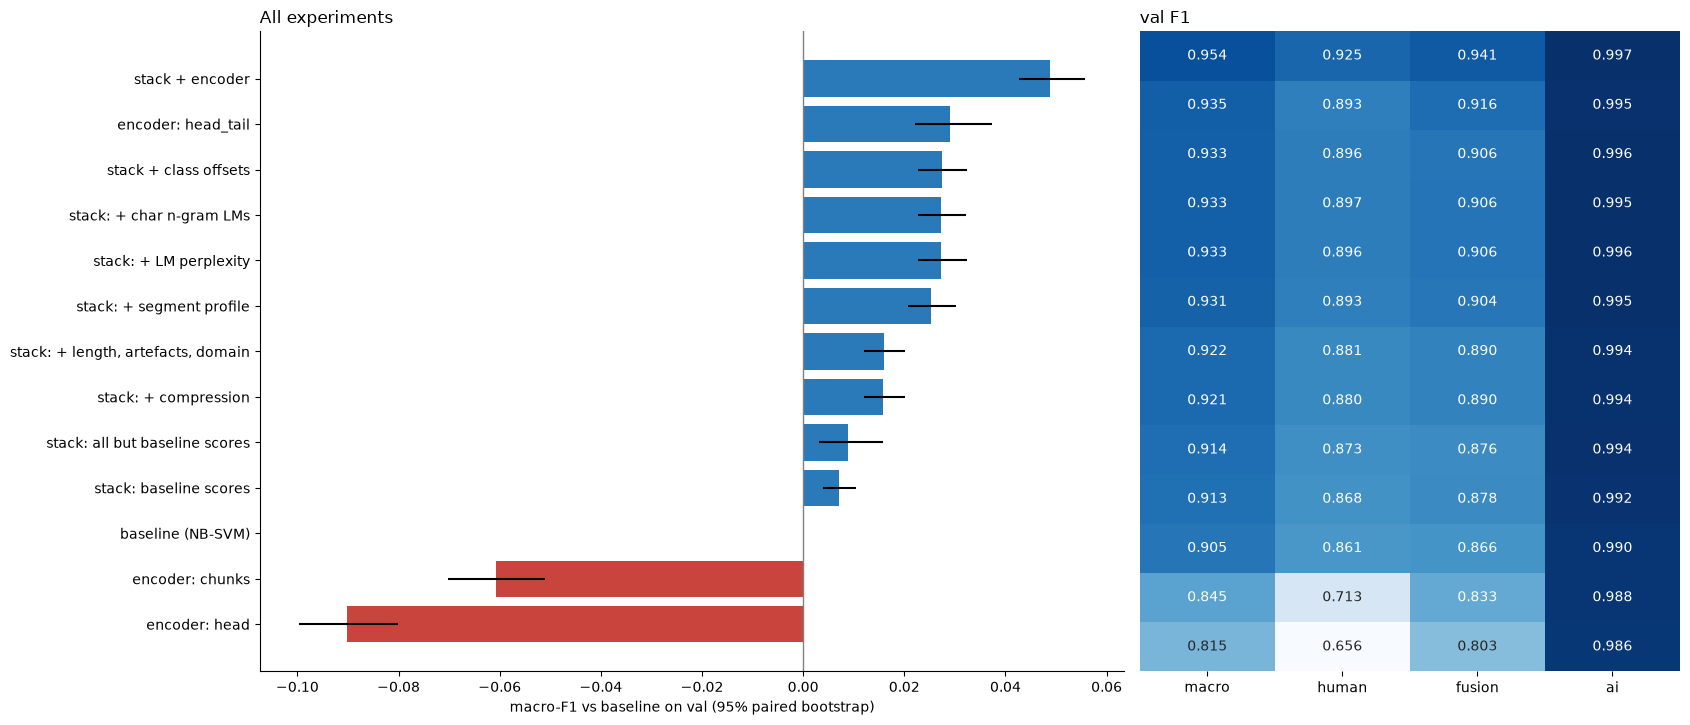

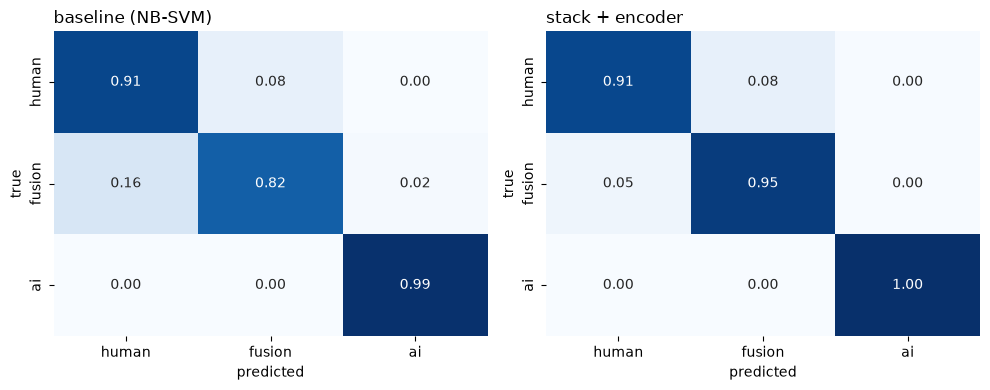

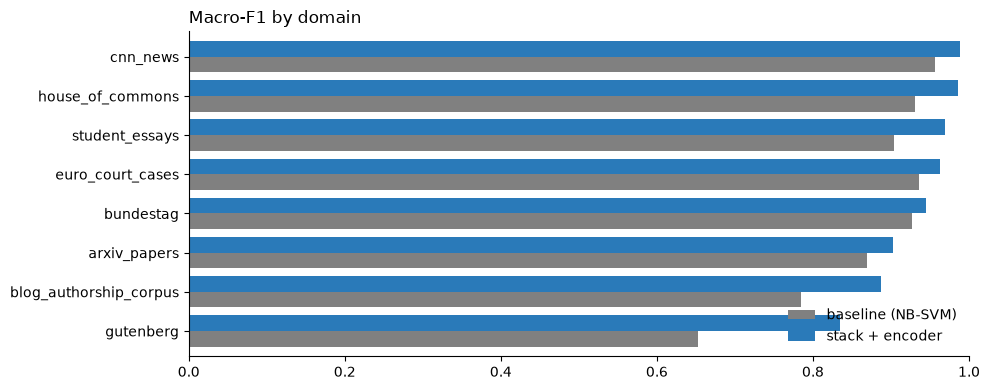

In [39]:
def paired_bootstrap(pred, reference, n=1000):
    rng = np.random.default_rng(SEED)
    y, a, b = y_val.to_numpy(), np.asarray(pred), np.asarray(reference)
    diffs = []
    for _ in range(n):
        rows = rng.integers(0, len(y), len(y))
        diffs.append(f1_score(y[rows], a[rows], average='macro') - f1_score(y[rows], b[rows], average='macro'))
    return np.percentile(diffs, [2.5, 97.5])


summary = pd.DataFrame(experiment_log).T
summary['delta'] = summary.macro_f1 - summary.loc[REFERENCE, 'macro_f1']
ci = pd.DataFrame({s: paired_bootstrap(val_predictions[s], val_predictions[REFERENCE]) for s in summary.index},
                  index=['ci_low', 'ci_high']).T
summary = summary.join(ci).sort_values('delta')
summary.to_csv(Path(RUNS) / f'experiment_log_{TAG}.csv')

fig, axes = plt.subplots(1, 2, figsize=(17, 0.45 * len(summary) + 1.5), gridspec_kw={'width_ratios': [1.6, 1]})
err = np.vstack([summary.delta - summary.ci_low, summary.ci_high - summary.delta])
axes[0].barh(summary.index, summary.delta, xerr=err, color=np.where(summary.delta > 0, COLORS['up'], COLORS['down']))
axes[0].axvline(0, color='gray', lw=1)
axes[0].set(xlabel='macro-F1 vs baseline on val (95% paired bootstrap)', title='All experiments')
sns.heatmap(summary[['macro_f1'] + [f'f1_{c}' for c in LABELS]].iloc[::-1], annot=True, fmt='.3f', cmap='Blues',
            cbar=False, yticklabels=False, xticklabels=['macro'] + LABELS, ax=axes[1])
axes[1].set_title('val F1')
plt.tight_layout()
plt.show()

best_step = summary.macro_f1.idxmax()
plot_confusions([REFERENCE, best_step])

domains = per_domain([REFERENCE, best_step])
fig, ax = plt.subplots(figsize=(10, 4))
domains.sort_values(best_step).plot.barh(ax=ax, color=['gray', COLORS['human']], width=0.8, xlim=(0, 1),
                                         title='Macro-F1 by domain')
ax.set_ylabel('')
ax.legend(frameon=False, loc='lower right')
plt.tight_layout()
plt.show()

## Submission

submission.csv = stack-encoder {'stack': 0.9329, 'stack-encoder': 0.9544}


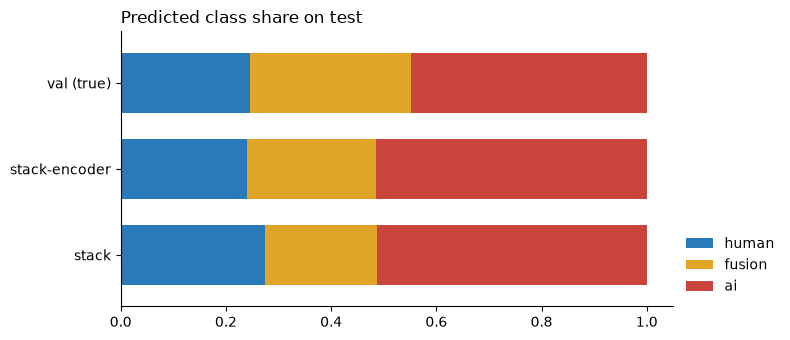

In [40]:
X_test = stack_matrix(FINAL_GROUPS, test_rows)
assert X_test.notna().all().all(), 'a feature group is missing test rows'
test_proba = pd.DataFrame(stack_model.predict_proba(X_test), columns=stack_model.classes_)[LABELS].to_numpy()

predictions = {'stack': apply_offsets(test_proba, [best_h, best_f, 0.0])}
val_steps = {'stack': 'stack + class offsets'}
if encoder_proba_all is not None:
    encoder_test = encoder_proba_all.loc[test_rows.index, [f'head_tail_{c}' for c in LABELS]].to_numpy()
    predictions['stack-encoder'] = np.array(LABELS)[(test_proba + encoder_test).argmax(1)]
    val_steps['stack-encoder'] = 'stack + encoder'

files = {}
for name, pred in predictions.items():
    file = sample_submission[['id']].merge(pd.DataFrame({'id': test_rows.index, 'label': pred}), on='id', how='left')
    if not SMOKE_TEST:
        assert len(file) == 25_000 and file.id.is_unique and file.label.isin(LABELS).all()
    files[name] = file
    file.to_csv(Path(RUNS) / f'submission-{name}.csv', index=False)

best_file = max(files, key=lambda n: experiment_log[val_steps[n]]['macro_f1'])
files[best_file].to_csv('submission.csv', index=False)
print('submission.csv =', best_file, {n: round(experiment_log[s]['macro_f1'], 4) for n, s in val_steps.items()})

shares = pd.DataFrame({name: f.label.value_counts(normalize=True) for name, f in files.items()}).reindex(LABELS)
shares['val (true)'] = y_val.value_counts(normalize=True).reindex(LABELS)
fig, ax = plt.subplots(figsize=(8, 3.5))
shares.T.plot.barh(stacked=True, ax=ax, color=palette, width=0.7, title='Predicted class share on test')
ax.legend(loc='lower left', bbox_to_anchor=(1, 0), frameon=False)
plt.tight_layout()
plt.show()

In [43]:
if SUBMIT and not SMOKE_TEST:
    load_kaggle_token()
    submitted = '\n'.join(get_ipython().getoutput(f'kaggle competitions submissions -c {COMPETITION} -v'))
    for name in files:
        message = f'{name} {TAG}'
        if message in submitted:
            print('already on Kaggle:', message)
            continue
        file = Path(RUNS) / f'submission-{name}.csv'
        !kaggle competitions submit -c {COMPETITION} -f "{file}" -m "{message}"
    !kaggle competitions submissions -c {COMPETITION}

100%|████████████████████████████████████████| 285k/285k [00:01<00:00, 277kB/s]
Submission ref: 58621577
4 submissions remaining today.
100%|████████████████████████████████████████| 286k/286k [00:01<00:00, 260kB/s]
Submission ref: 58621582
3 submissions remaining today.
Successfully submitted to AI-Generated Text Detection | HW3 | UCU AI 2026     ref  fileName                      date                        description         status                    publicScore  privateScore  
--------  ----------------------------  --------------------------  ------------------  ------------------------  -----------  ------------  
58621582  submission-stack-encoder.csv  2026-11-20 16:14:31.857000  stack-encoder full  SubmissionStatus.PENDING                             
58621577  submission-stack.csv          2026-11-20 16:14:26.847000  stack full          SubmissionStatus.PENDING                             
